# TikTok BNPL corpus: analysis

Builds the labelled, pseudonymized corpus from `data/raw/tiktok/` and produces the tables in `outputs/tiktok/tables/`, the figures in `outputs/figures/tiktok/`, and `outputs/tiktok/findings_summary.md`. Rerunning regenerates everything from the raw files.

**How to read this notebook.** The corpus is public TikTok content from accounts registered in Italy that names a BNPL provider or phrase. It is not a sample of the 20-27 study population: the API reports no age. Post types, creator types, and theme cues are transparent text rules defined in `scripts/tiktok_terms.py`; percentages are *mention rates* in captions, hashtags, and automatic transcripts, not validated prevalence. Only aggregates are displayed. Each result is followed by a short interpretation.

## Validity and bias

These results describe what was posted publicly on one platform. They are not
measurements of how young adults in Italy use BNPL. Read every number with the
following biases in mind.

**One platform, not the whole media environment.** TikTok is one app among
many: Instagram, YouTube, Facebook, Telegram, and the providers' own apps and
websites are not covered. TikTok has its own formats, such as short videos,
TikTok Shop, and affiliate content, and its own recommendation algorithm.
Results such as "91% of BNPL videos are shop ads" hold for TikTok and cannot
be generalized to social media as a whole.

**The link to young adults is an assumption, not a measurement.** The thesis
studies 20-27 year olds. The Research API returns no age for creators or
viewers. Using TikTok rests on a working hypothesis: TikTok's audience skews
young, with the 18-24 group commonly reported as its largest age group, so
BNPL content on TikTok approximates what young adults in Italy are exposed to.
Before relying on this hypothesis, the thesis should:

- cite a current audience source for Italy, such as DataReportal or
  Audiweb/AGCOM, with its date;
- state that the hypothesis concerns exposure, not use;
- keep in mind that creators are not viewers, so a shop's video can be posted
  by anyone and watched by anyone.

**Selection bias in what was collected.**
- `region_code` is the country where the creator's account is registered. It
  is not the viewer's country or the language, and Italian accounts post some
  content in other languages.
- API keyword search covers descriptions only, so videos that mention BNPL
  only in speech or on screen are missed unless a hashtag matches.
- The search terms were chosen in a pilot. Different terms would give a
  different corpus, and colloquial or misspelled mentions are under-covered.
- Only public videos still online at collection time are included. Deleted,
  private, and moderated videos are missing, which may remove the most
  critical or problematic content.
- TikTok does not document how complete Research API results are. Weekly
  counts swing by up to ±40% without an obvious cause, which points to
  variation in coverage.
- Comments were collected for the most-commented videos only, which favours
  popular videos. Profiles cover a selected subset of creators.

**Measurement error in the labels.** Post types, creator types, and themes are
keyword rules applied to short, informal text. They miss irony, negation,
slang, and anything shown only in the video. Reading samples showed that about
half of the "personal experience" posts are creator product reviews. The rules
were checked by reading samples, not formally validated: there is no
precision, recall, or inter-rater agreement estimate. If the thesis relies on
a label-based share, a validation check would make it defensible. This means
hand-labelling a random sample, about 100 videos per post type, and reporting
the agreement with the rules.

**What the statistics can and cannot support.**
- The corpus is everything the API returned for the query, not a random
  sample of a defined population. Population-level significance tests about
  "Italian TikTok" or "young Italians" would therefore not be meaningful, and
  the analysis does not run any. The figures are descriptive.
- Where a number rests on few videos, the analysis shows how stable it is.
  This treats posting as a random process; it is not sampling error.
  - Shares carry 95% Wilson intervals, which suit small counts and rates
    near zero.
  - Median views carry 95% percentile bootstrap intervals (2,000 resamples,
    seed 42).
  - The Black Friday index is compared with the same index computed around
    every other week, shown as a 5-95% band.

  These intervals do not cover selection bias, label error, or API coverage.
  A narrow interval means a number is stable, not that it is correct.
- Rare categories rest on small numbers: 159 commentary videos, 37
  first-person posts, and 0-26 discourse posts a month. Their intervals are
  wide, so changes are claimed only where intervals do not overlap, for
  example when comparing years rather than months. Counts are always reported
  with their denominators.
- Monthly volumes are expressed per day, because months differ in length by
  up to 10%.
- Content is concentrated: 100 accounts produce 47% of videos. Shares
  therefore partly reflect the habits of a few hundred shops rather than
  broad behaviour.
- Trends over time mix three things: changes in BNPL, TikTok's own growth,
  and changes in API coverage. Compare shapes and shares, not absolute
  levels, and do not read growth in posts as growth in BNPL use.
- Engagement counts are a single snapshot taken at collection time and are
  shaped by the recommendation algorithm. Views keep growing after posting,
  so engagement is compared only for videos at least 90 days old at
  collection. The comparison remains descriptive.

**What makes the conclusions valid.** Claims stay within what the data can
carry:

- they concern public content from accounts registered in Italy that matches
  these terms;
- they report counts with denominators and state the collection date;
- they are triangulated with the thesis's survey and interviews, which do
  measure the 20-27 population.

The search query, field list, collection log, and labelling rules are all
recorded (`query_config.json`, `collection_log.jsonl`,
`scripts/tiktok_terms.py`). Anyone can therefore reproduce the corpus
definition and check how each label was assigned.


## How to read the uncertainty

The corpus is everything the API returned, not a random sample, so there is no sampling error in the usual sense. Intervals are shown only where a number rests on few videos. Each one asks how much a rate could move if posting were a random process.

- **Shares:** 95% Wilson intervals. They are suitable for small counts and for rates near zero.
- **Median views:** 95% percentile bootstrap intervals (2,000 resamples, seed 42).
- **Black Friday:** the same index computed around every other week, shown as a 5-95% band.

Large groups, such as the 88,403 shop ads, have intervals narrower than a percentage point, so they are not drawn.

None of these intervals covers the biases described above: selection, keyword measurement, and API coverage. A narrow interval means a rate is stable, not that it is correct.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, display

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / 'scripts').is_dir(): PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT))
pd.set_option('display.float_format', lambda value: f'{value:,.3f}')
from scripts import tiktok_analysis as analysis

result = analysis.run_analysis()
plt.close('all')
tables = result['tables']


def show(name):
    display(Image(filename=str(analysis.FIGURES_TIKTOK / f'{name}.png'), width=820))

## 1. Corpus and coverage

In [2]:
monthly = tables['monthly']
complete = monthly.loc[monthly['complete'], 'month']
display(result['funnel'])
print(f"Fully collected months: {complete.iloc[0]} to {complete.iloc[-1]} ({len(complete)} months)")
print(f"Creators: {result['corpus']['creator_id'].nunique():,}; "
      f"profiled: {int(result['creators']['profiled'].sum()):,}; "
      f"comments: {len(result['comments']):,}")
videos_per_creator = result['corpus']['creator_id'].value_counts()
print(f"Share of videos by the 10 / 100 most active creators: "
      f"{videos_per_creator.head(10).sum() / len(result['corpus']):.0%} / "
      f"{videos_per_creator.head(100).sum() / len(result['corpus']):.0%}")

,step,videos
0,records returned by the API,98641
1,unique video IDs,98641
2,"BNPL provider or phrase in description, hashta...",97166


Fully collected months: 2024-01 to 2026-08 (32 months)
Creators: 8,099; profiled: 997; comments: 18,078
Share of videos by the 10 / 100 most active creators: 15% / 47%


**Interpretation.** The search is precise: 97,166 of the 98,641 videos returned (98.5%) name a BNPL provider or phrase. The trend analysis uses the 32 fully collected months, January 2024 to August 2026. The weeks from 14 September to 18 October 2026 are still pending, because the daily video quota was reached; rerun the collection notebook to add them.

Production is concentrated. 8,099 accounts posted BNPL content, but the 100 most active accounts produced 47% of all videos and the top 10 produced 15%. Creator profiles cover 997 of the 2,348 selected accounts so far, again because of the daily quota. Comments cover 309 videos, which are the most-commented videos of each post type. Only 20% of videos have an automatic transcript, so captions and hashtags carry most of the signal.

*These figures describe the run of 26 October 2026. Rerunning the notebooks updates the tables and figures, but not this text.*

## 2. Volume over time

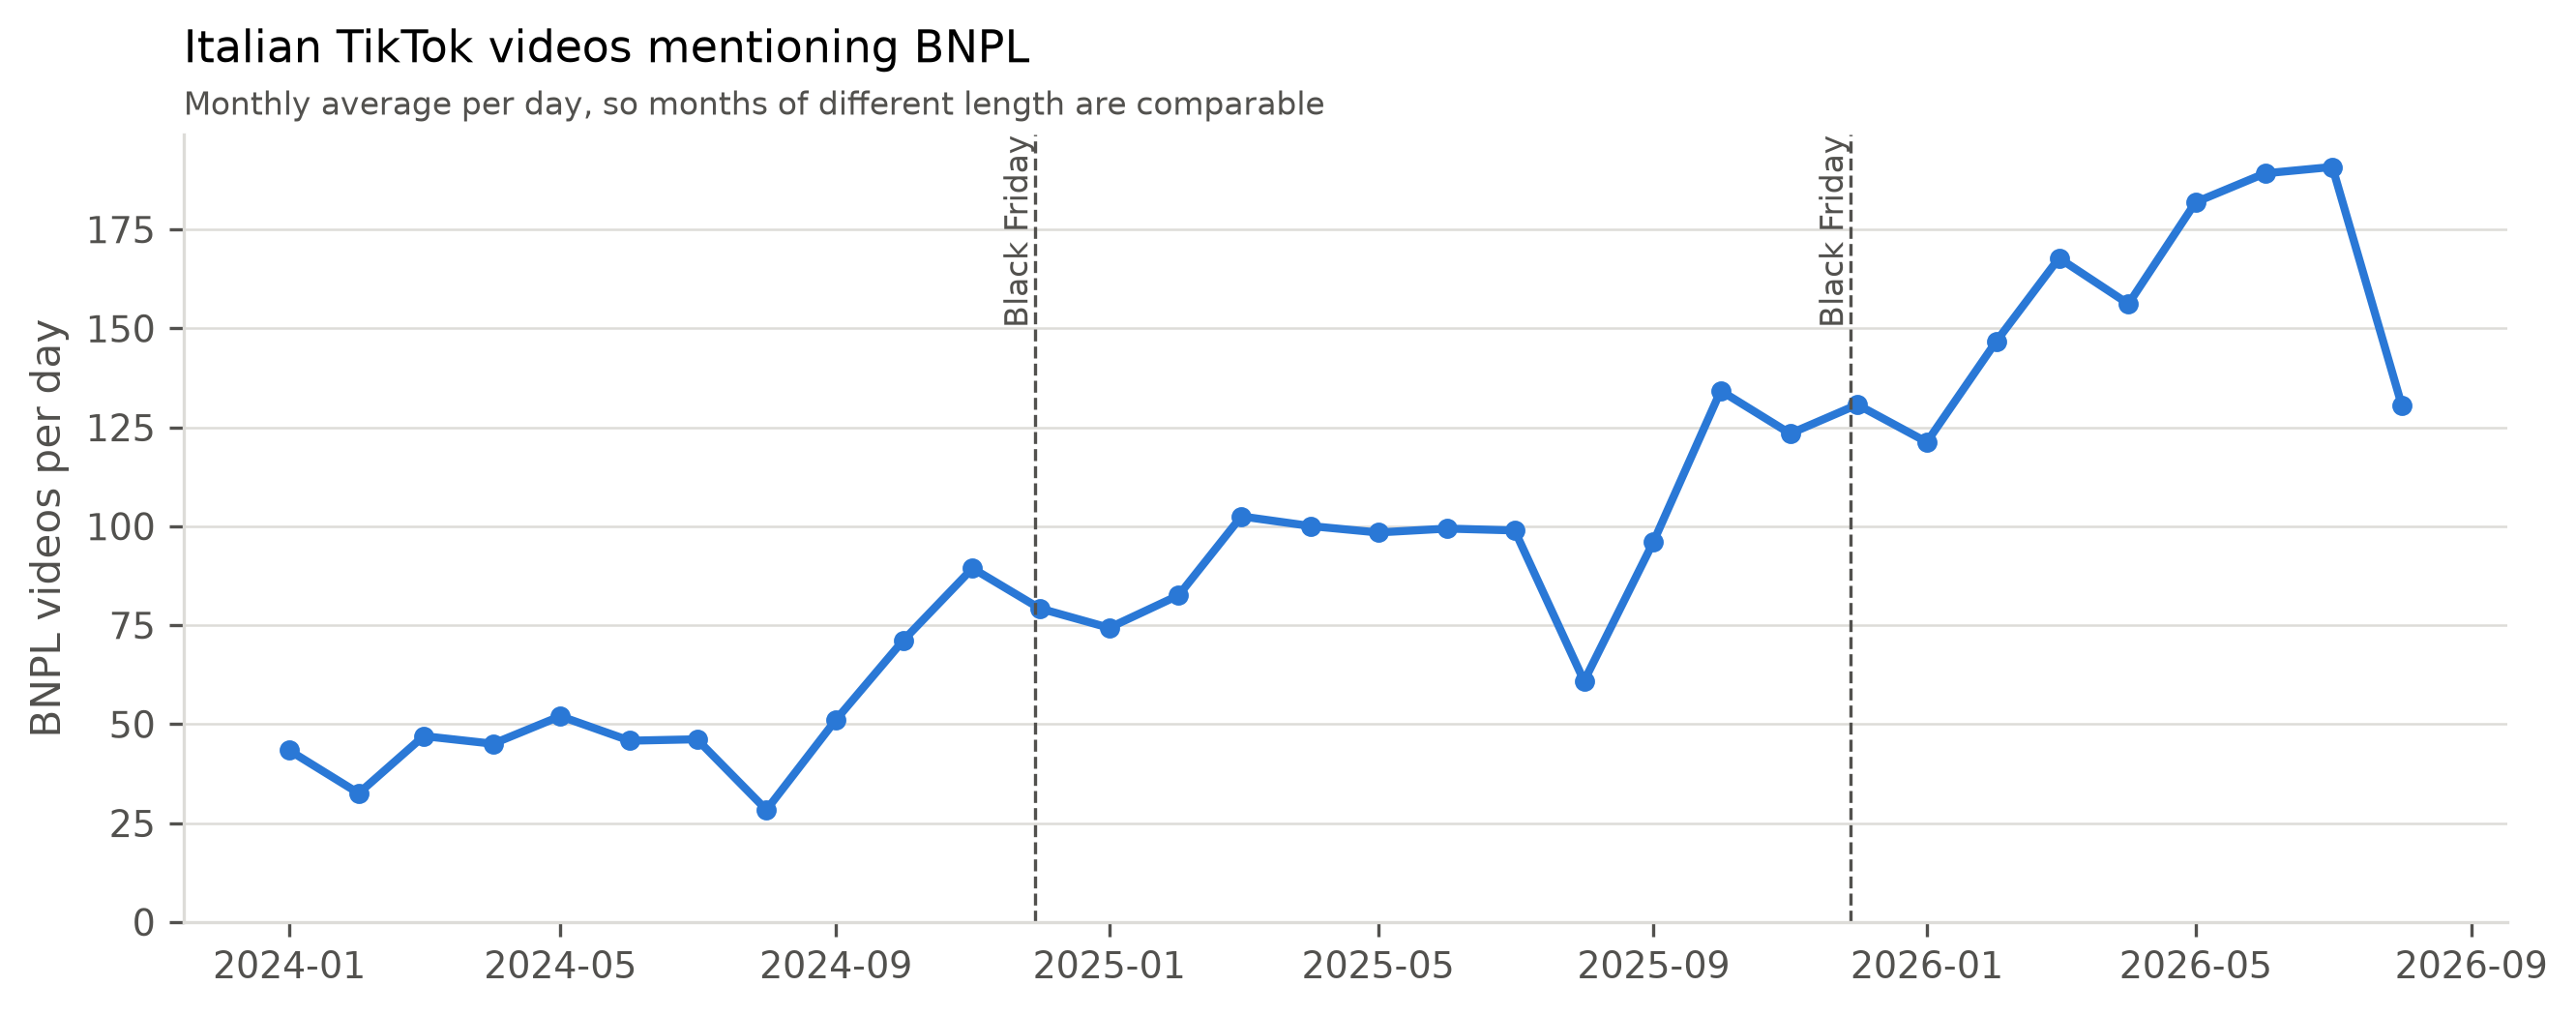

In [3]:
show('monthly_volume')

**Interpretation.** BNPL content on Italian TikTok roughly quadrupled in two and a half years. It went from about 44 videos a day in the first half of 2024 to about 187 a day in May-July 2026, peaking in July 2026 at 191 a day. The chart uses videos per day, so that February is not lower simply because it is shorter. The growth comes in steps, in autumn 2024 (September-November) and in autumn 2025 (September-October), rather than evenly.

August is the low point every year, at 28, 61, and 131 videos a day. That fits the summer closure of the small shops that produce most of the content (see section 3).

The trend combines real growth in BNPL as a checkout option with growth of TikTok itself and changes in API coverage. It shows that exposure is rising, not by how much usage is rising.

## 3. Who posts, and what kind of post

,post_type,videos,creators,share,share_low,share_high,engagement_videos,median_views,median_views_low,median_views_high,median_likes,median_comments,median_shares
0,personal_experience,37,25,0.000,0.000,0.001,28,"5,274.500","1,760.500","11,963.000",53.000,5.500,3.000
1,financial_commentary,159,137,0.002,0.001,0.002,128,"1,387.500",919.500,"2,078.287",19.000,0.000,1.000
2,shop_ad,88403,6956,0.910,0.908,0.912,81994,"1,057.000","1,047.000","1,066.000",13.000,0.000,1.000
3,other,8567,2001,0.088,0.086,0.090,7906,854.500,834.000,868.000,11.000,0.000,1.000


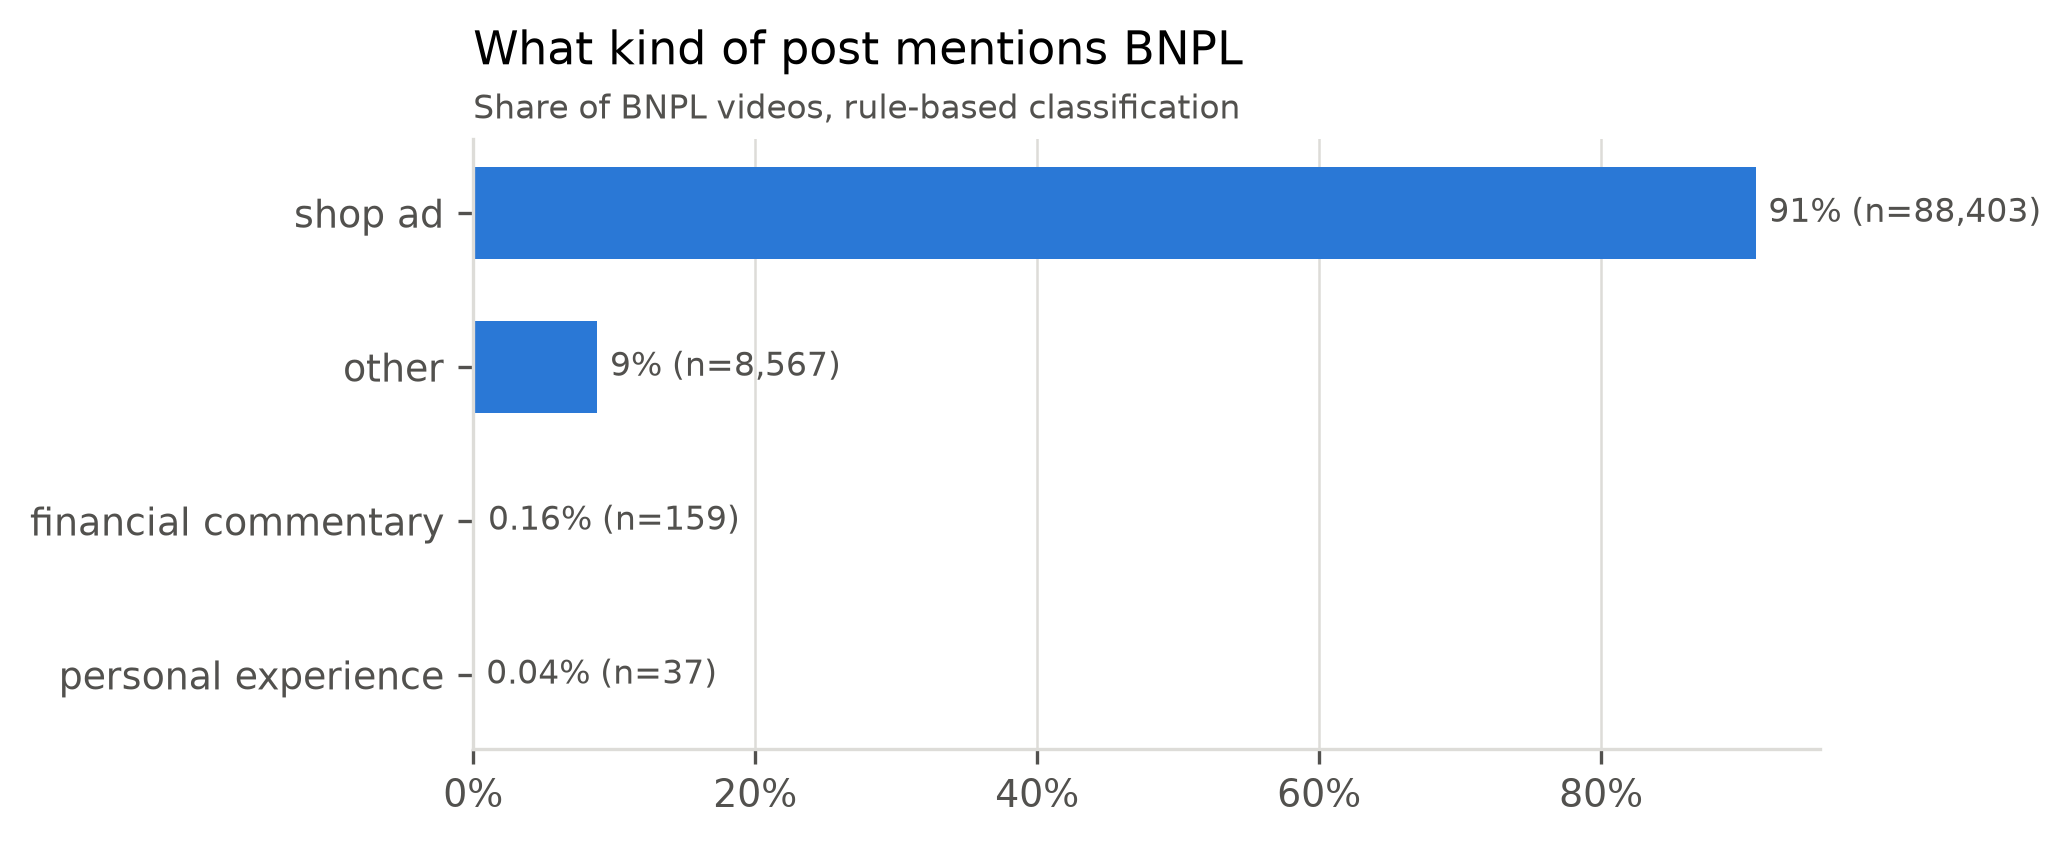

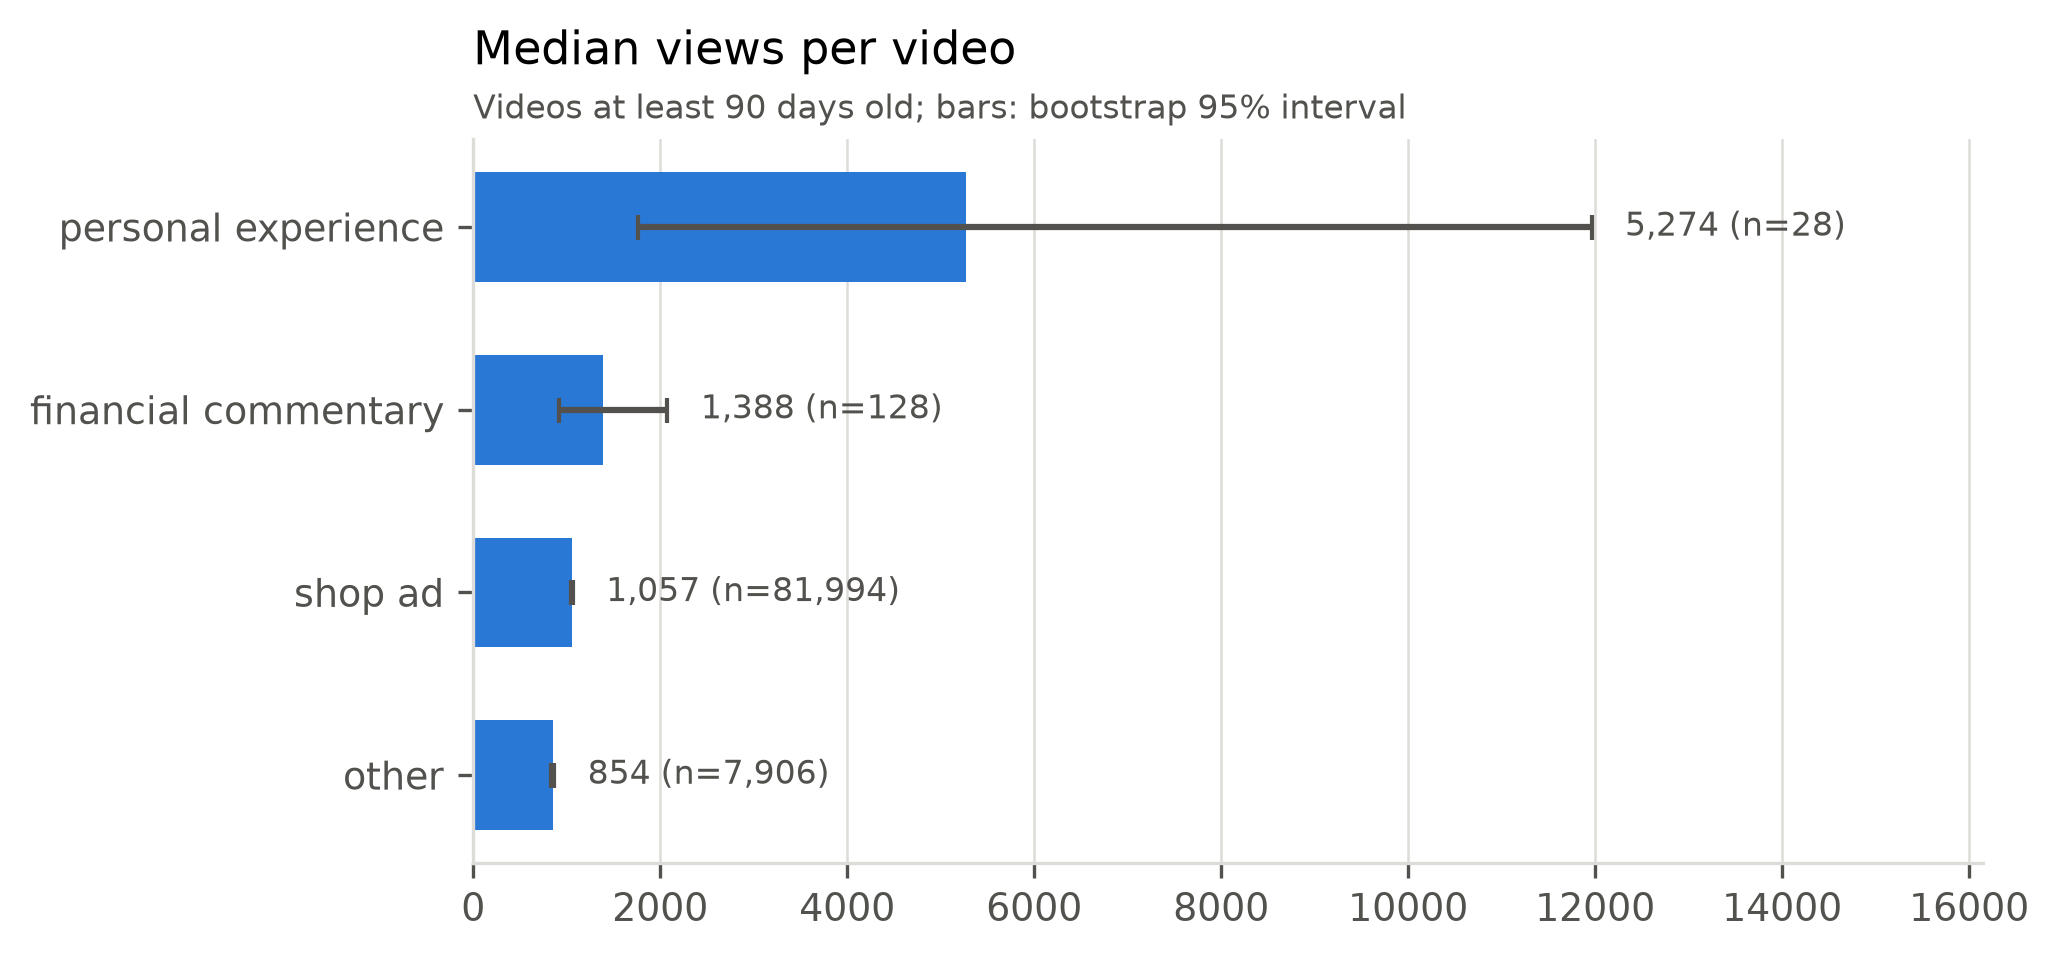

In [4]:
display(tables['post_types'])
show('post_types')
show('engagement_by_post_type')

**Interpretation.** On Italian TikTok, BNPL is overwhelmingly a merchant's selling argument rather than a topic people discuss.
- **Shop ads:** 91.0% of videos (95% interval 90.8-91.2%). Shops and services list "paga in 3 rate con Klarna/Scalapay" next to prices, shipping, and WhatsApp contacts.
- **Other:** 8.8%, mostly hashtag-only posts from the same kind of accounts.
- **Financial commentary:** 159 videos, 0.16% (0.14-0.19%). These are explainers, warnings, and news.
- **First-person posts:** 37 videos, 0.04%. Reading them shows that about half are creator product reviews rather than independent accounts of using BNPL.

Engagement is compared only for videos at least 90 days old when collected, because recent videos have not finished collecting views.
- **Commentary vs ads:** commentary has a median of 1,388 views (95% interval 920-2,078) and ads 1,057 (1,047-1,066). The intervals overlap, so there is no evidence that critical content reaches more people than an ad.
- **First-person posts:** a median of 5,274 views, above every other group, but the interval is very wide (1,761-11,963) and rests on 28 videos. Read it as a tendency, not a result.

For the thesis: young adults who meet BNPL on TikTok meet it mainly as a promotional checkout feature, not as credit discussed by peers.

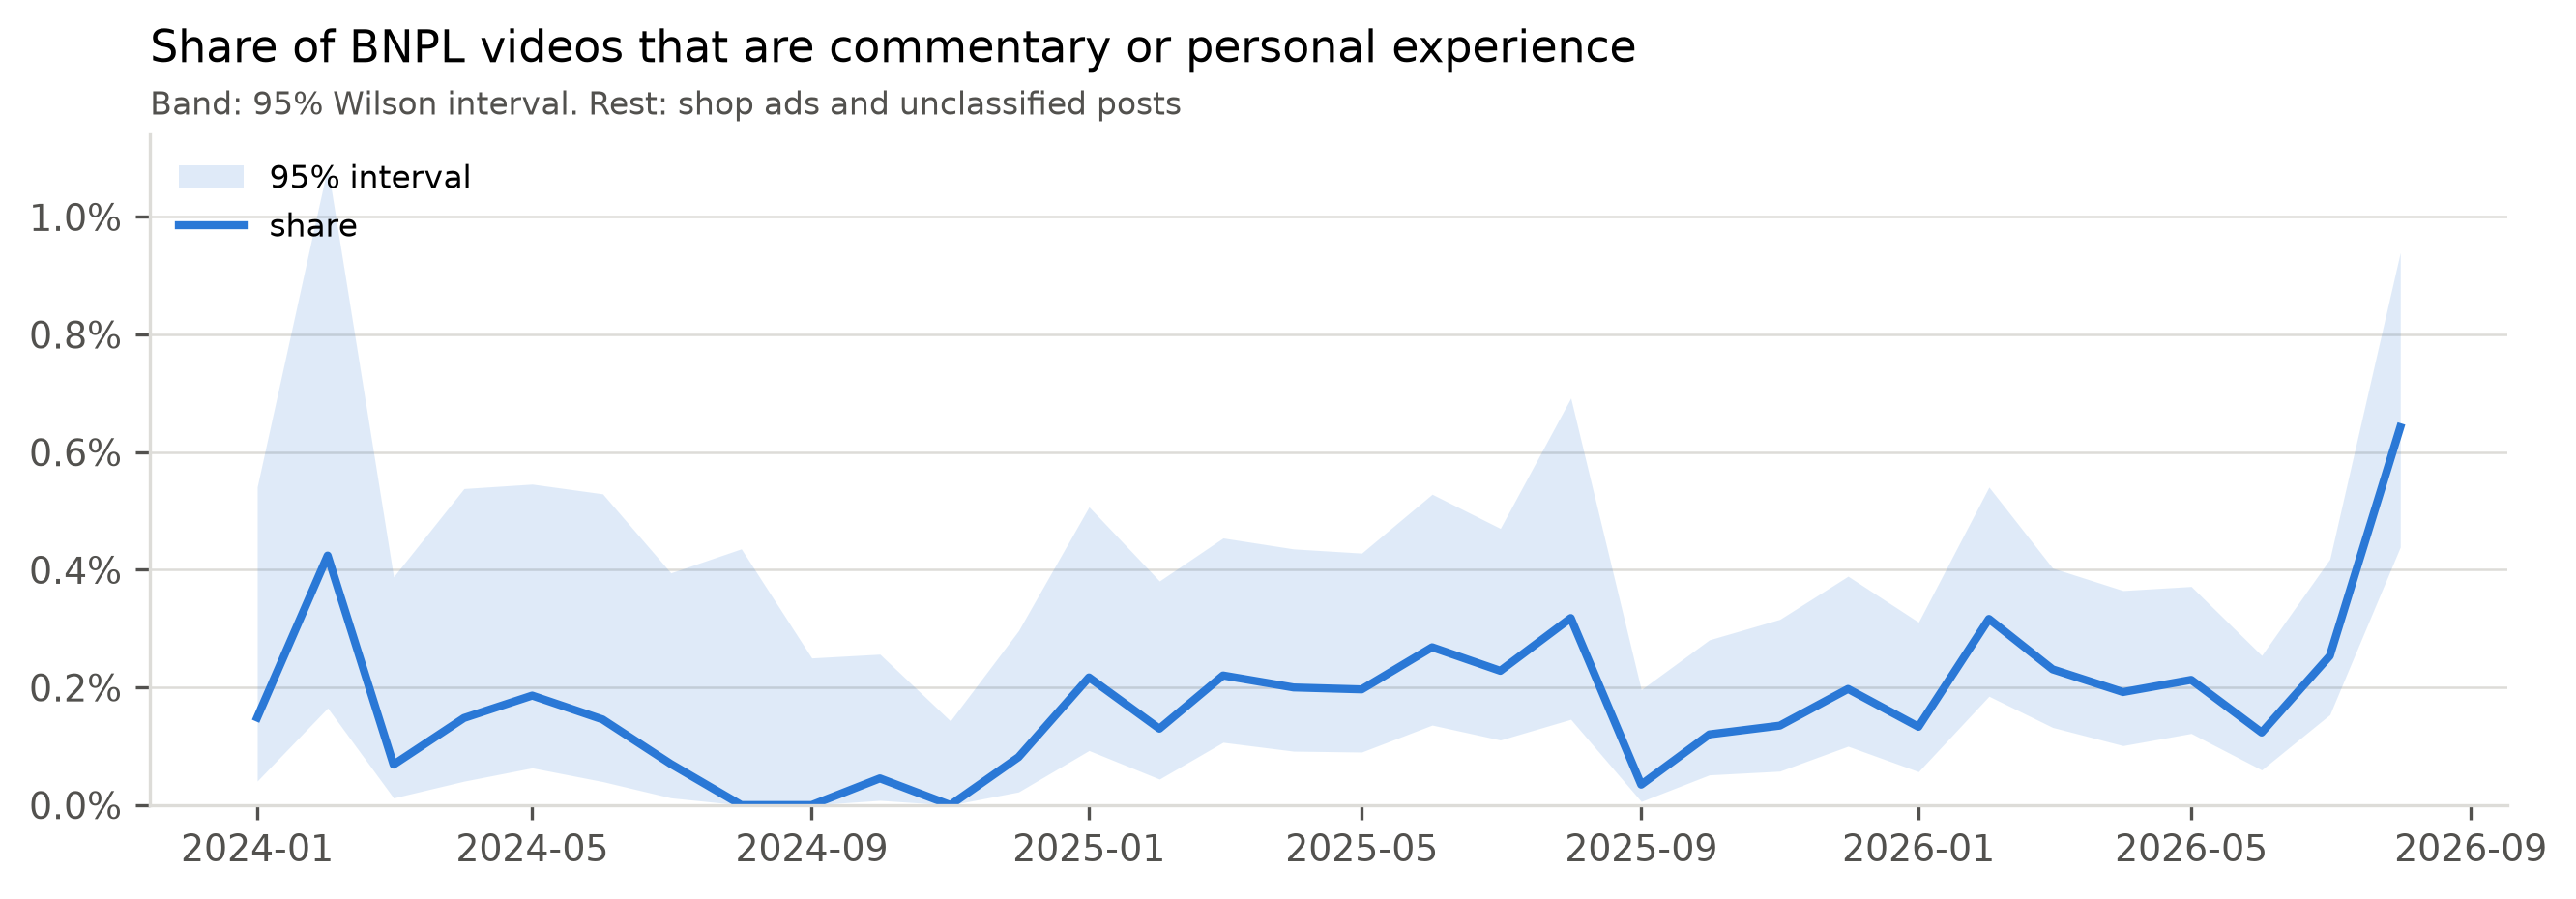

In [5]:
show('discourse_share')

**Interpretation.** The monthly share of commentary and first-person posts is noisy, because it rests on 0-26 posts a month. The shaded 95% interval shows this. For example, the 0.42% in February 2024 comes from 4 posts, and its interval runs from 0.17% to 1.09%.

Pooled by year over fully collected months, the trend is clear:

| Year | Discourse posts | Share | 95% interval |
|---|---|---|---|
| 2024 | 18 | 0.09% | 0.06-0.15% |
| 2025 | 67 | 0.18% | 0.14-0.23% |
| 2026 (January-August) | 99 | 0.25% | 0.21-0.31% |

The 2024 and 2026 intervals do not overlap, so critical and personal content grew faster than BNPL content overall. Commentary alone rose from 14 videos in 2024 to 60 in 2025 and 76 in January-August 2026.

August 2026 is the highest month (0.64%, interval 0.44-0.94%), but its interval overlaps several earlier months, so it is suggestive rather than conclusive. Its content is coherent all the same. Posts discuss paying for groceries in installments (one post reports a Rome supermarket chain adding Klarna at the till that month), borrowing for summer holidays, and the coming change in the law.

,creator_type,creators,share
0,merchant_brand,493,0.494
1,ordinary_user,442,0.443
2,finfluencer_educator,46,0.046
3,news_institution,14,0.014
4,unknown,1,0.001
5,provider_official,1,0.001


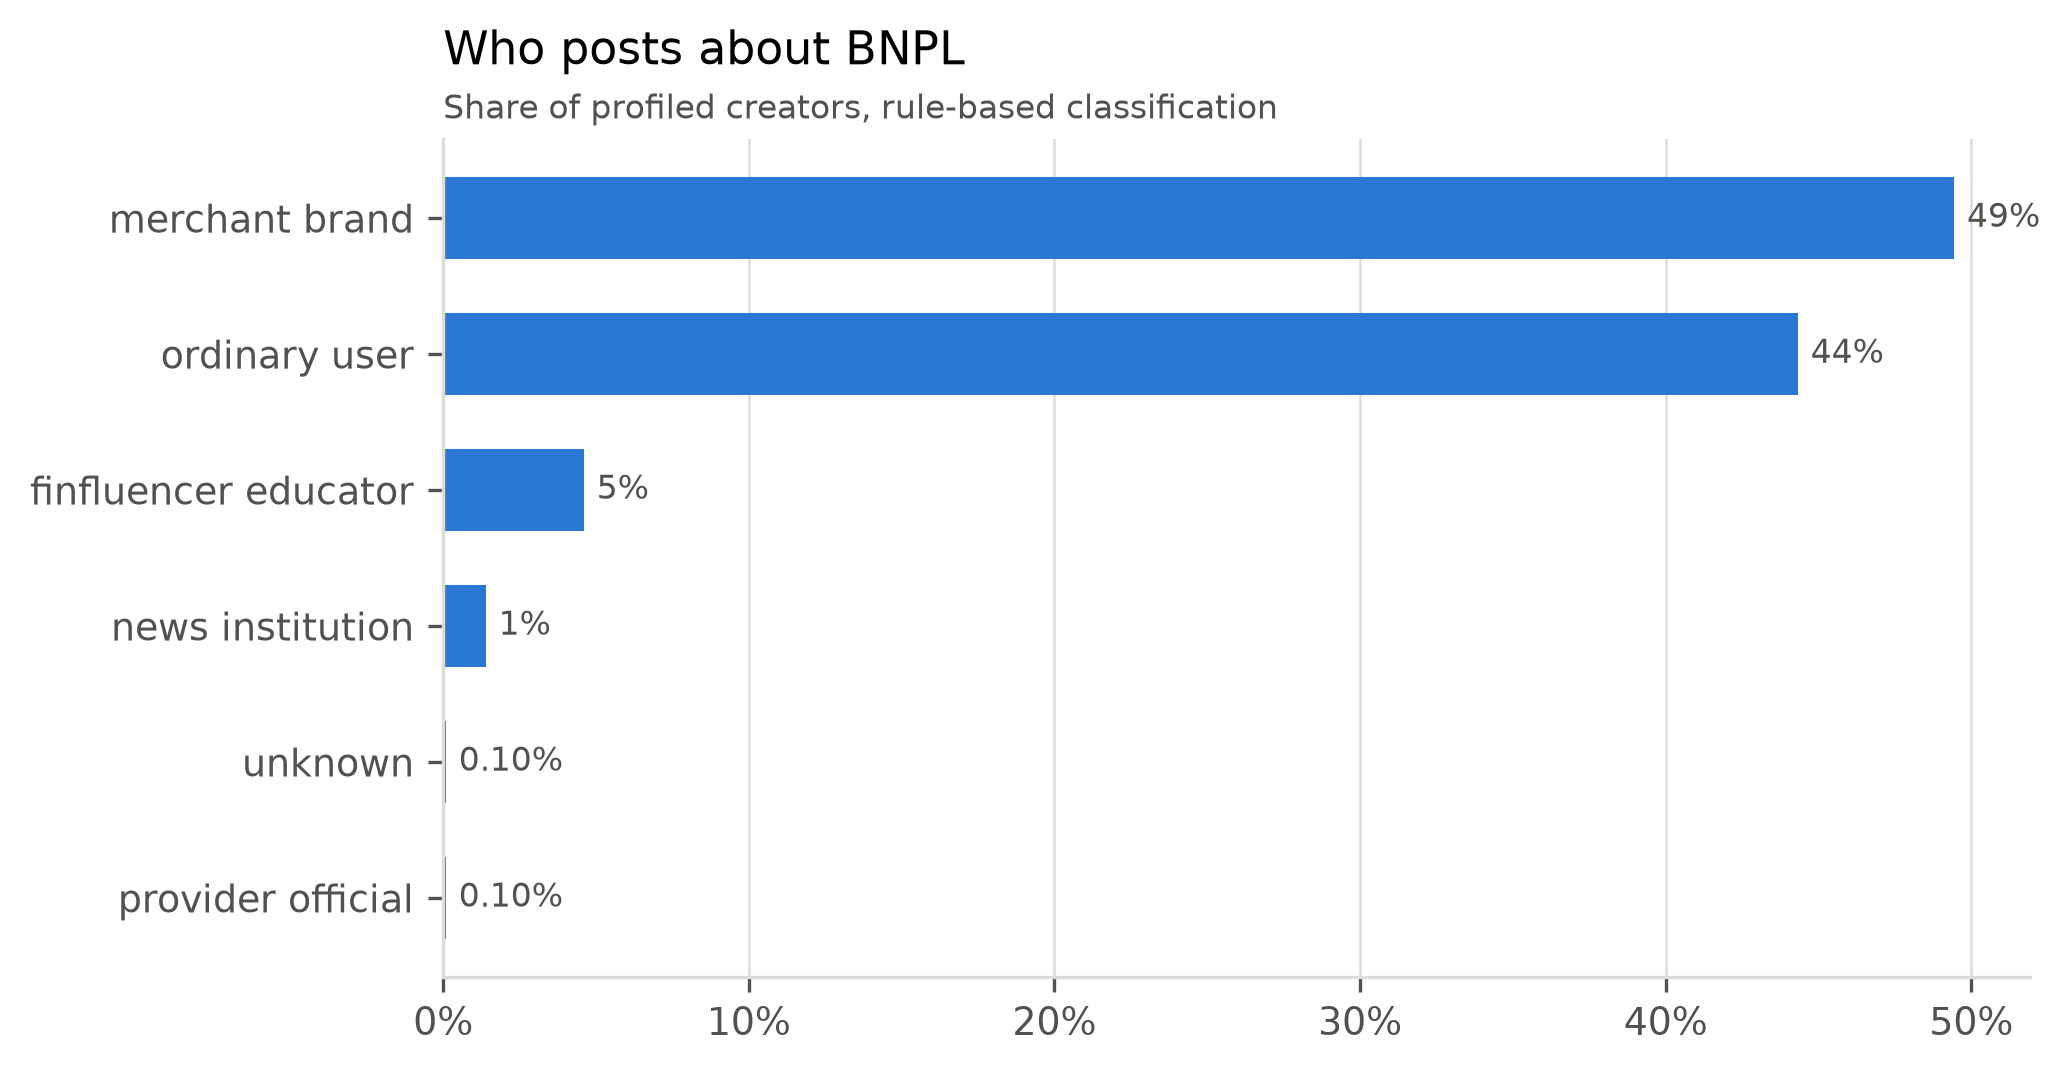

In [6]:
display(tables['creator_types'])
show('creator_types')

**Interpretation.** Among the 997 profiled creators, 49% are merchants and 44% have ordinary profiles. Finfluencers and educators make up 5%, and news outlets and institutions 1%.

Only one profile belongs to a BNPL provider. Providers do not promote BNPL on Italian TikTok themselves; the merchants who offer it at checkout do.

The share of ordinary profiles is overstated, for two reasons:
- every creator of a non-ad post was profiled on purpose;
- many small shops have no bio and post BNPL in only a few videos, so the rules cannot recognize them as merchants.

The remaining profiles will be added when the collection is rerun.

## 4. Providers

,provider,videos,creators,share_shop_ad
0,klarna,68966,5784,0.907
1,scalapay,28256,1964,0.936
2,heylight,3107,484,0.930
3,paypal_pay_in_3,2593,290,0.988
4,pagodil,1197,217,0.846
5,amazon_installments,7,6,0.714
6,soisy,2,2,1.000


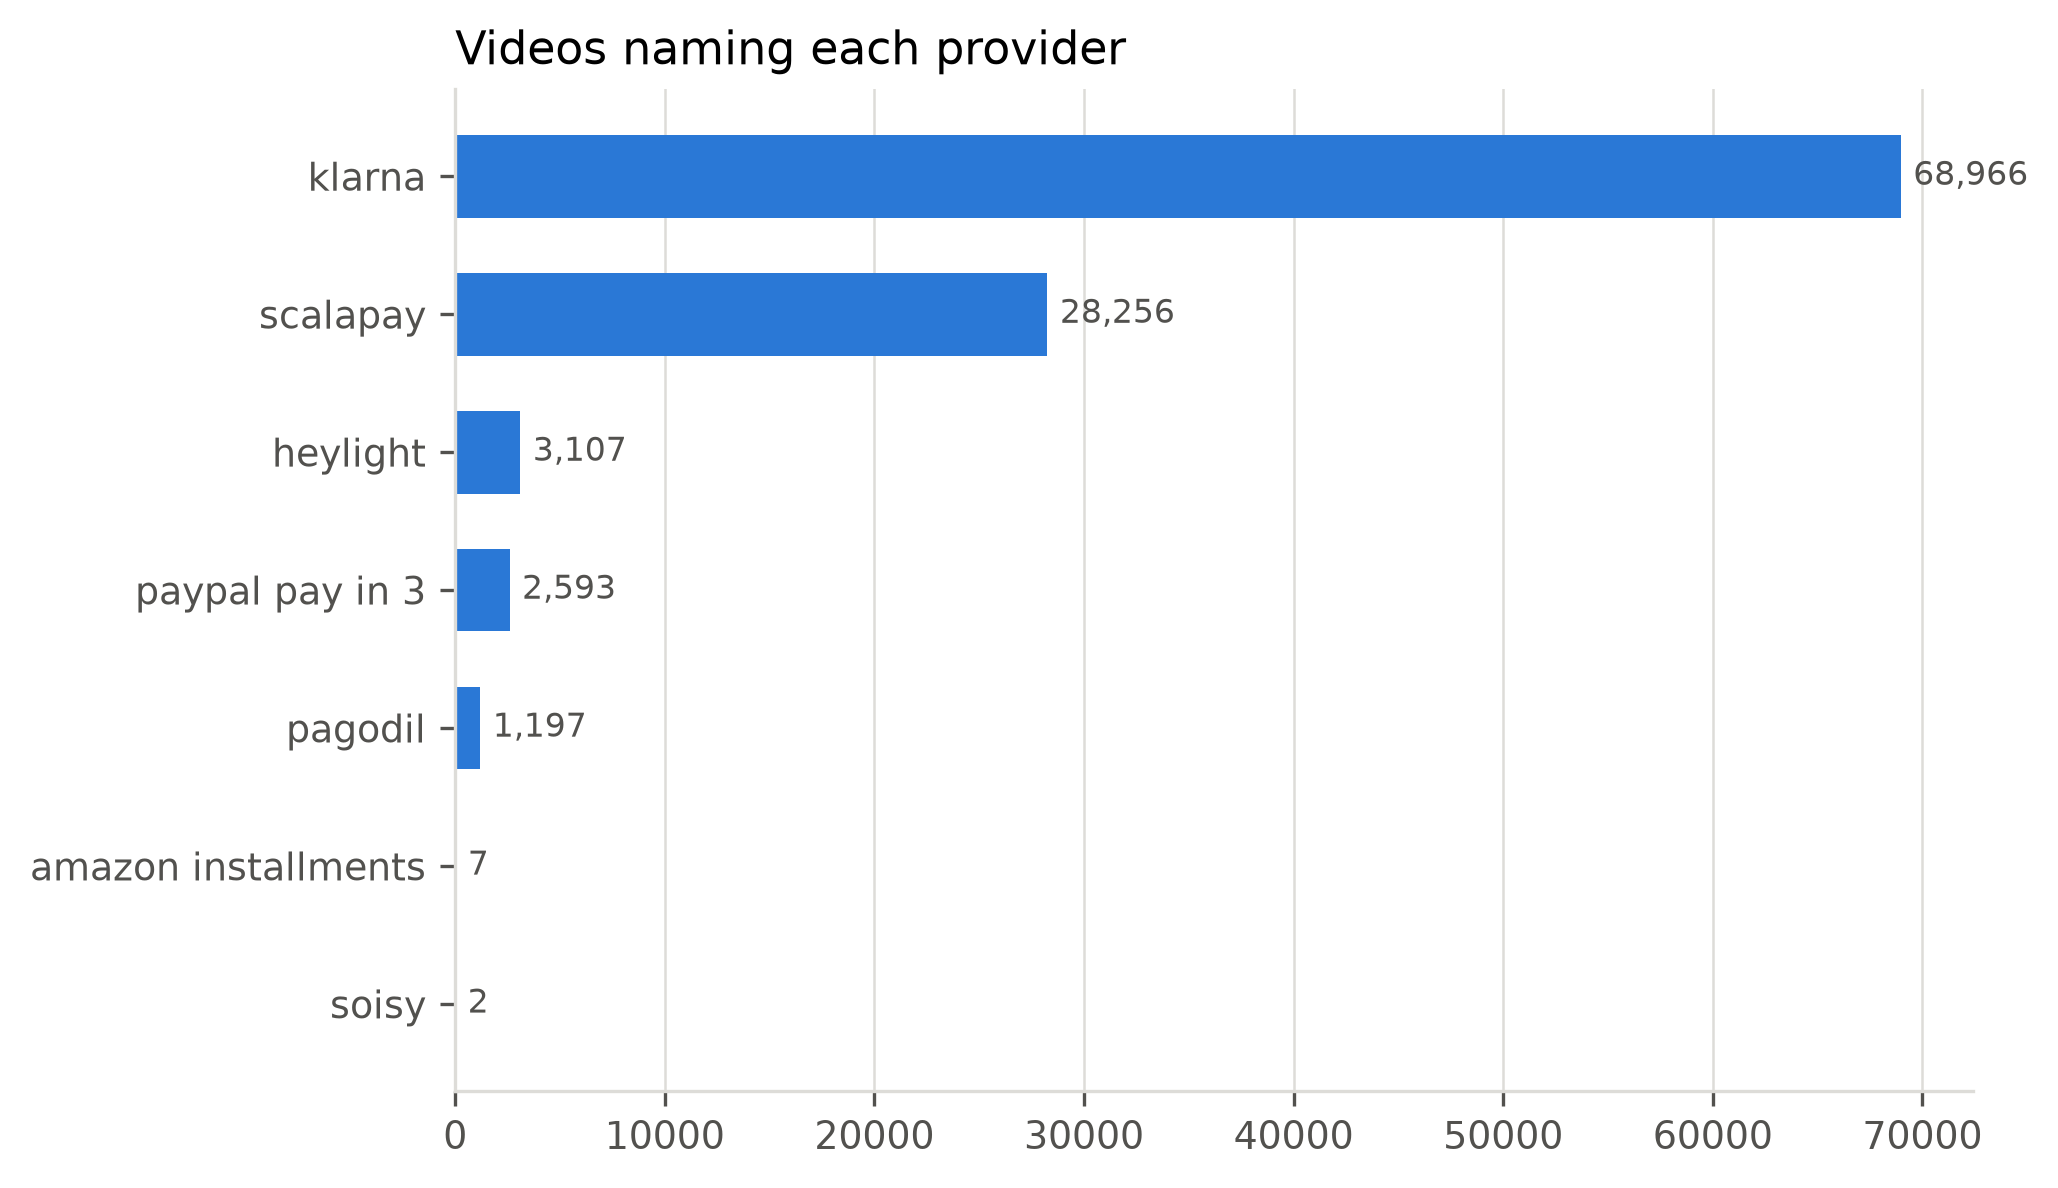

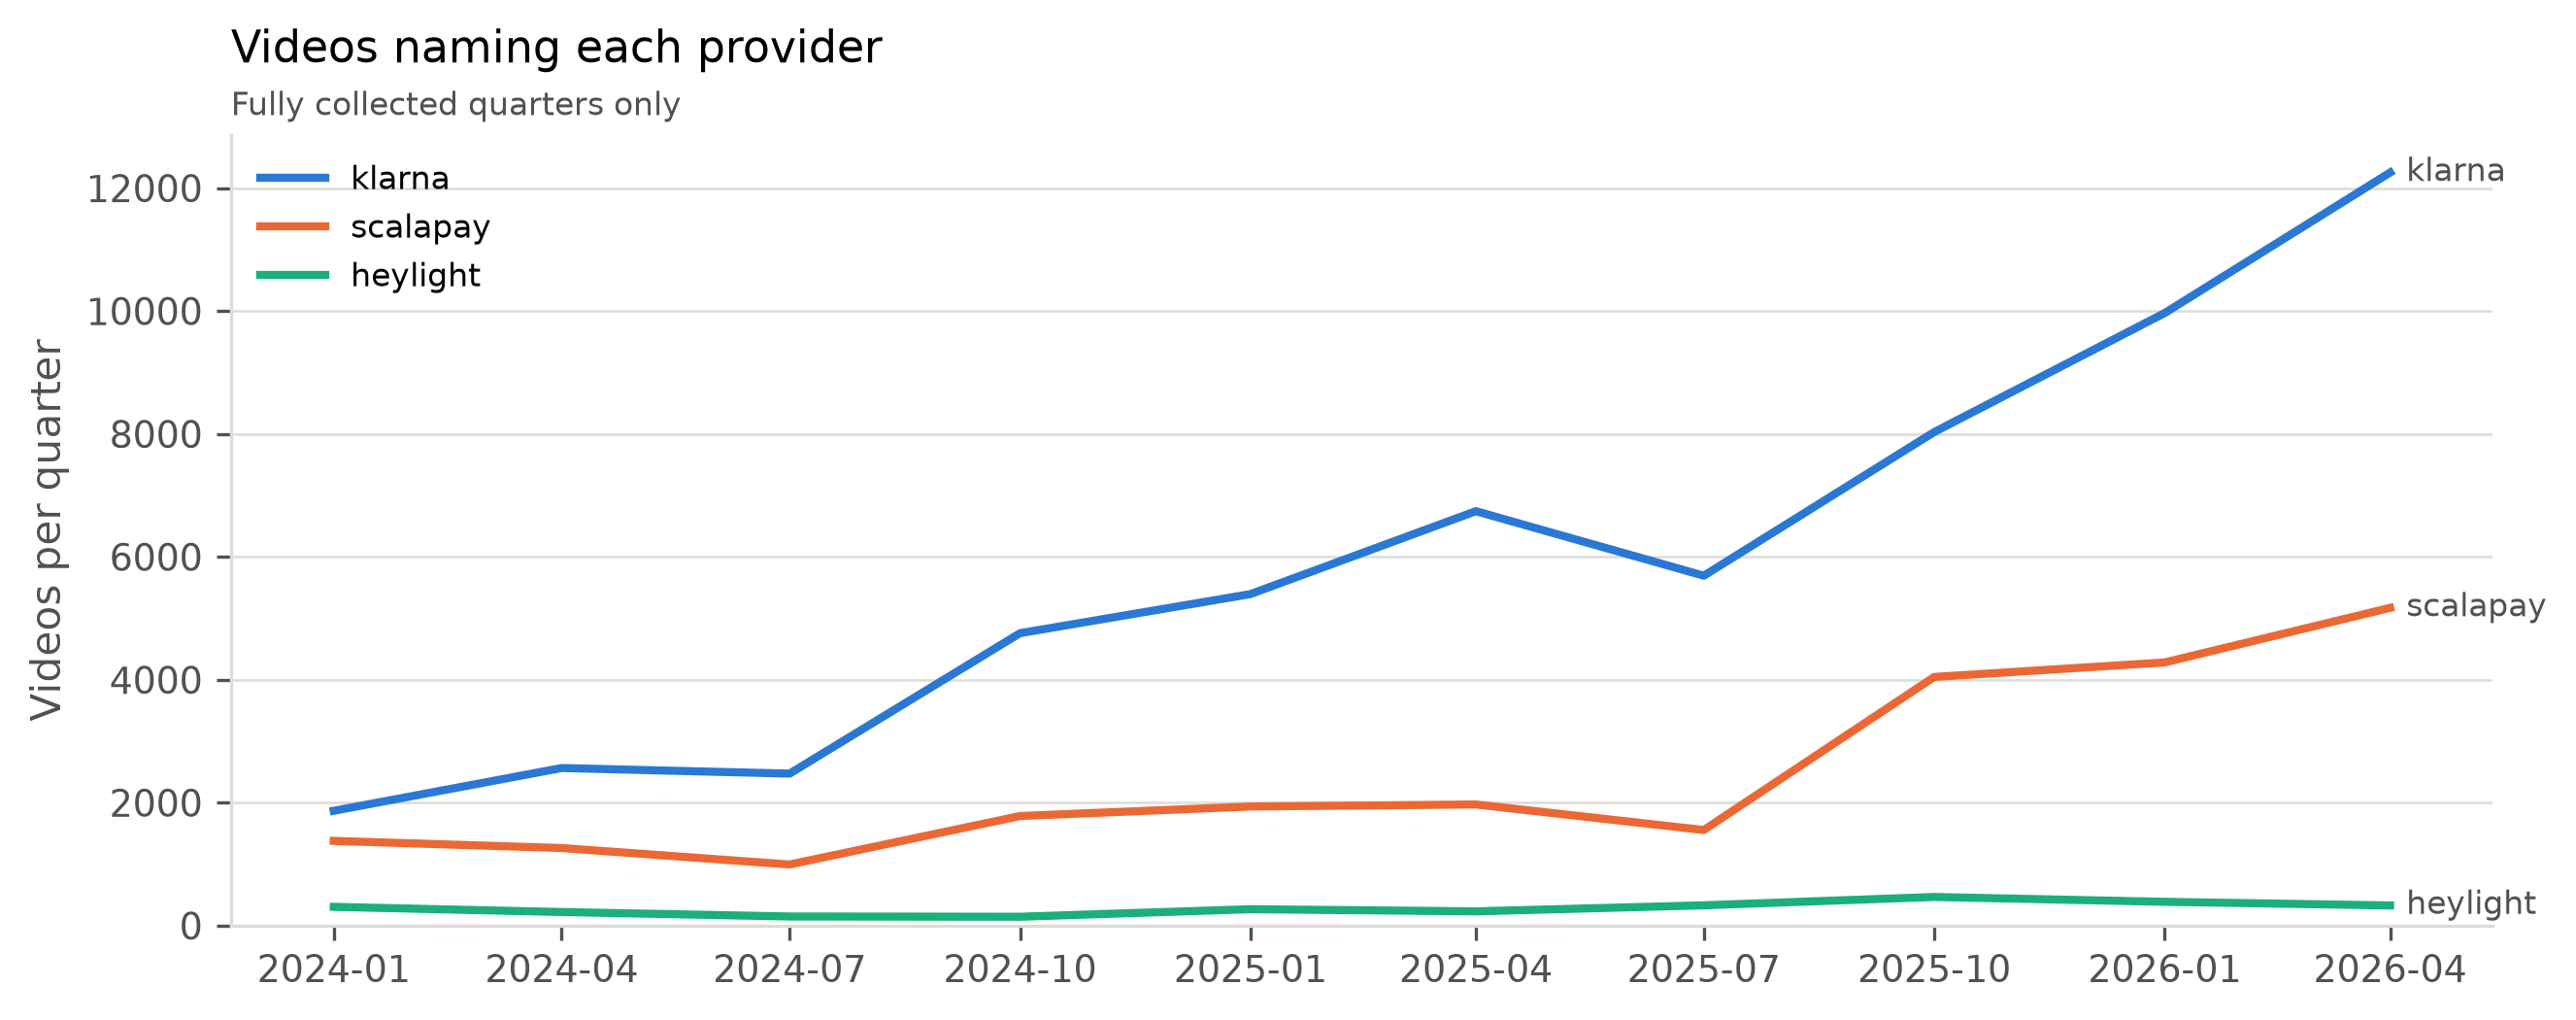

In [7]:
display(tables['providers'])
show('providers')
show('provider_trends')

**Interpretation.** Klarna is the default BNPL brand on Italian TikTok. It accounts for 66% of all provider mentions: 68,966 videos from 5,784 accounts. Next come:
- Scalapay: 28,256 videos;
- HeyLight: 3,107;
- PayPal's pay in 3: 2,593;
- PagoDIL: 1,197.

Every provider appears in ads 85-99% of the time.

Growth differs by provider. From the first quarter of 2024 to the second quarter of 2026, Klarna mentions grew 6.6 times (1,868 to 12,253) and Scalapay 3.8 times (1,378 to 5,170), with Scalapay jumping in Q4 2025. HeyLight and PagoDIL stayed flat.

Almost one in five videos that names a provider (17.9%, interval 17.7-18.2%) names two or more, typically "paga con Klarna o Scalapay". The same shopper is routinely offered several providers side by side. This is the platform-level counterpart of the fragmentation across providers and apps that the thesis studies.

## 5. Themes mentioned

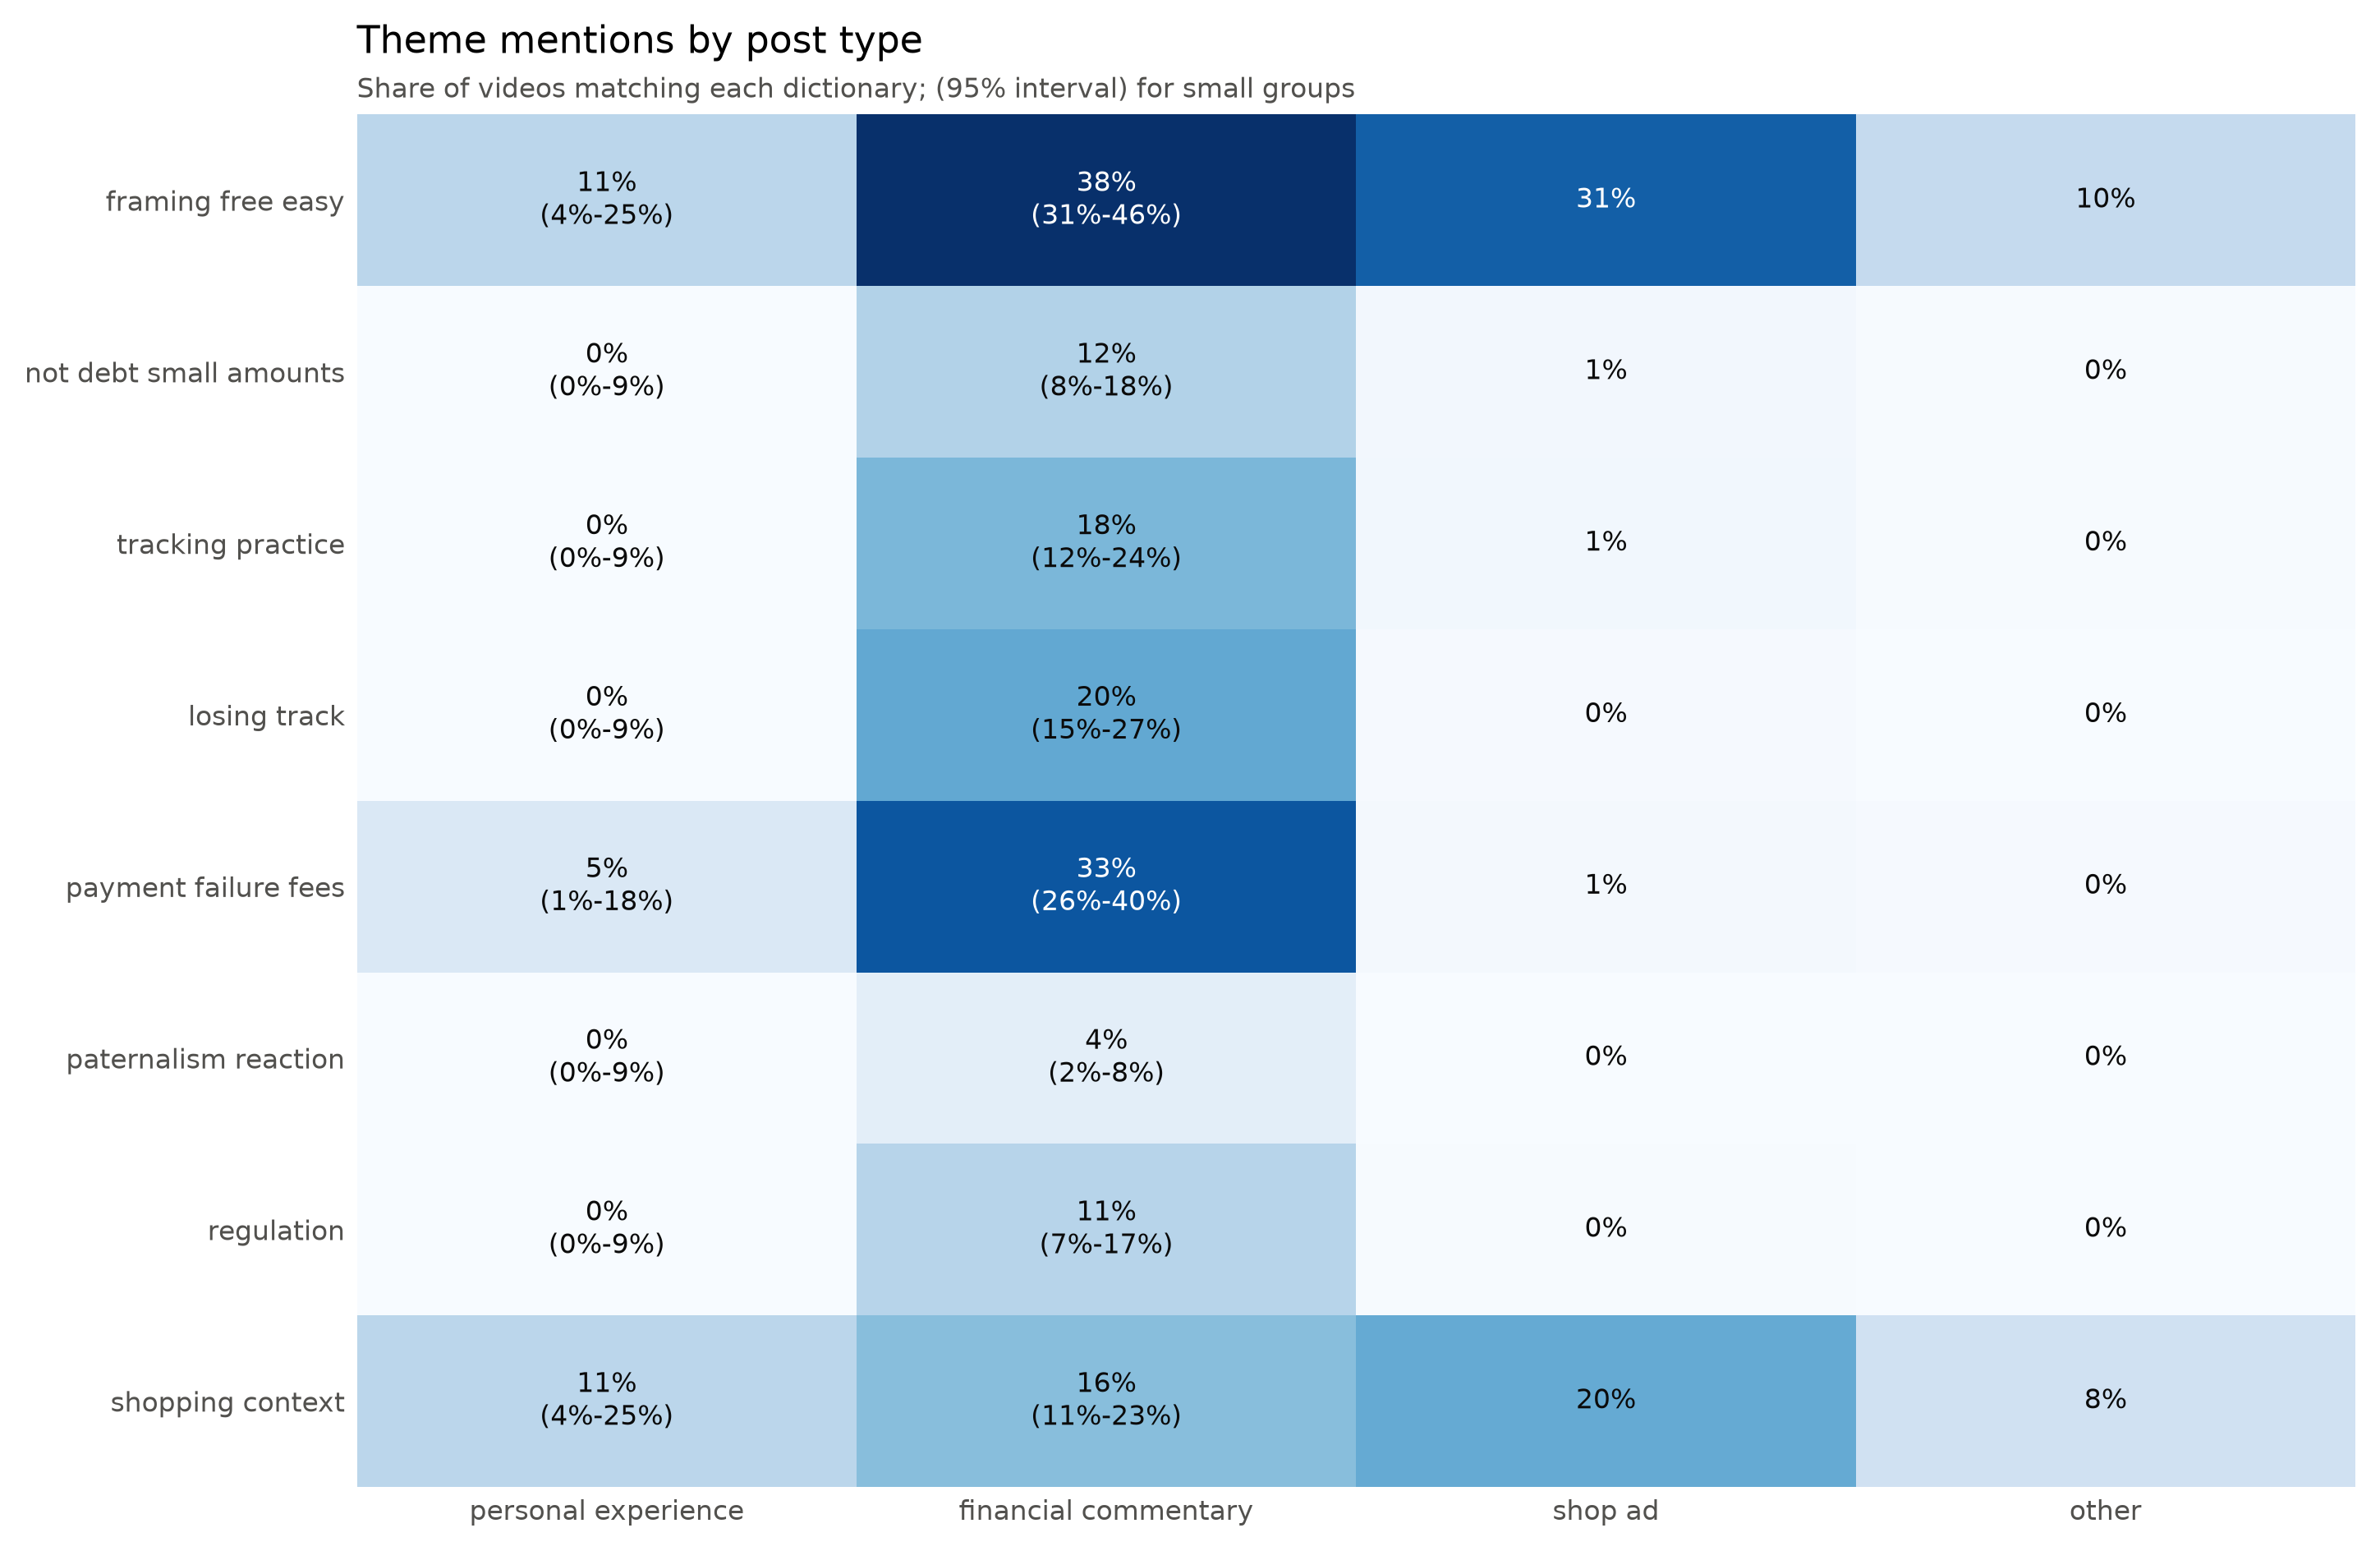

In [8]:
show('cues_by_post_type')

**Interpretation.** The two main post types tell two different stories about the same product. The 95% intervals in the commentary column are wide but do not reach zero.

**Shop ads.** The dominant message is that BNPL is free and easy: 31% of ads (31.1-31.8%) say "senza interessi", "0%", "comodo", or similar. Risk themes (fees, missed payments, losing track) appear in at most 1% of ads.

**Financial commentary.** The picture reverses:
- payment failure and fees: 33% (26-40%);
- losing track of installments: 20% (15-27%);
- tracking practices: 18% (12-24%);
- the "it's not debt, it's only a few euros" framing, usually quoted in order to challenge it: 12% (8-18%);
- regulation: 11% (7-17%).

Commentary also quotes the free-and-easy language (38%, 31-46%), mostly to contest it. Typical arguments are that "3 rate senza interessi" is "a credit contract, not a harmless button", or that "30 € + 25 € + 40 € + 50 €" adds up without being noticed.

This is the visibility problem the thesis addresses, voiced by educators. It reaches far fewer viewers than the free-and-easy message, because it is a fraction of a percent of the content.

First-person posts are too few (37) for comparisons: their intervals span 0-25%. Purchase enquiries are measured for comments only and are left out of this chart.

## 6. Black Friday

year,2024,2025
week_offset,,
-6,80.000,99.000
-5,85.000,105.000
-4,86.000,116.000
-3,92.000,55.000
-2,138.000,103.000
-1,119.000,122.000
0,68.000,115.000
1,107.000,115.000
2,117.000,110.000


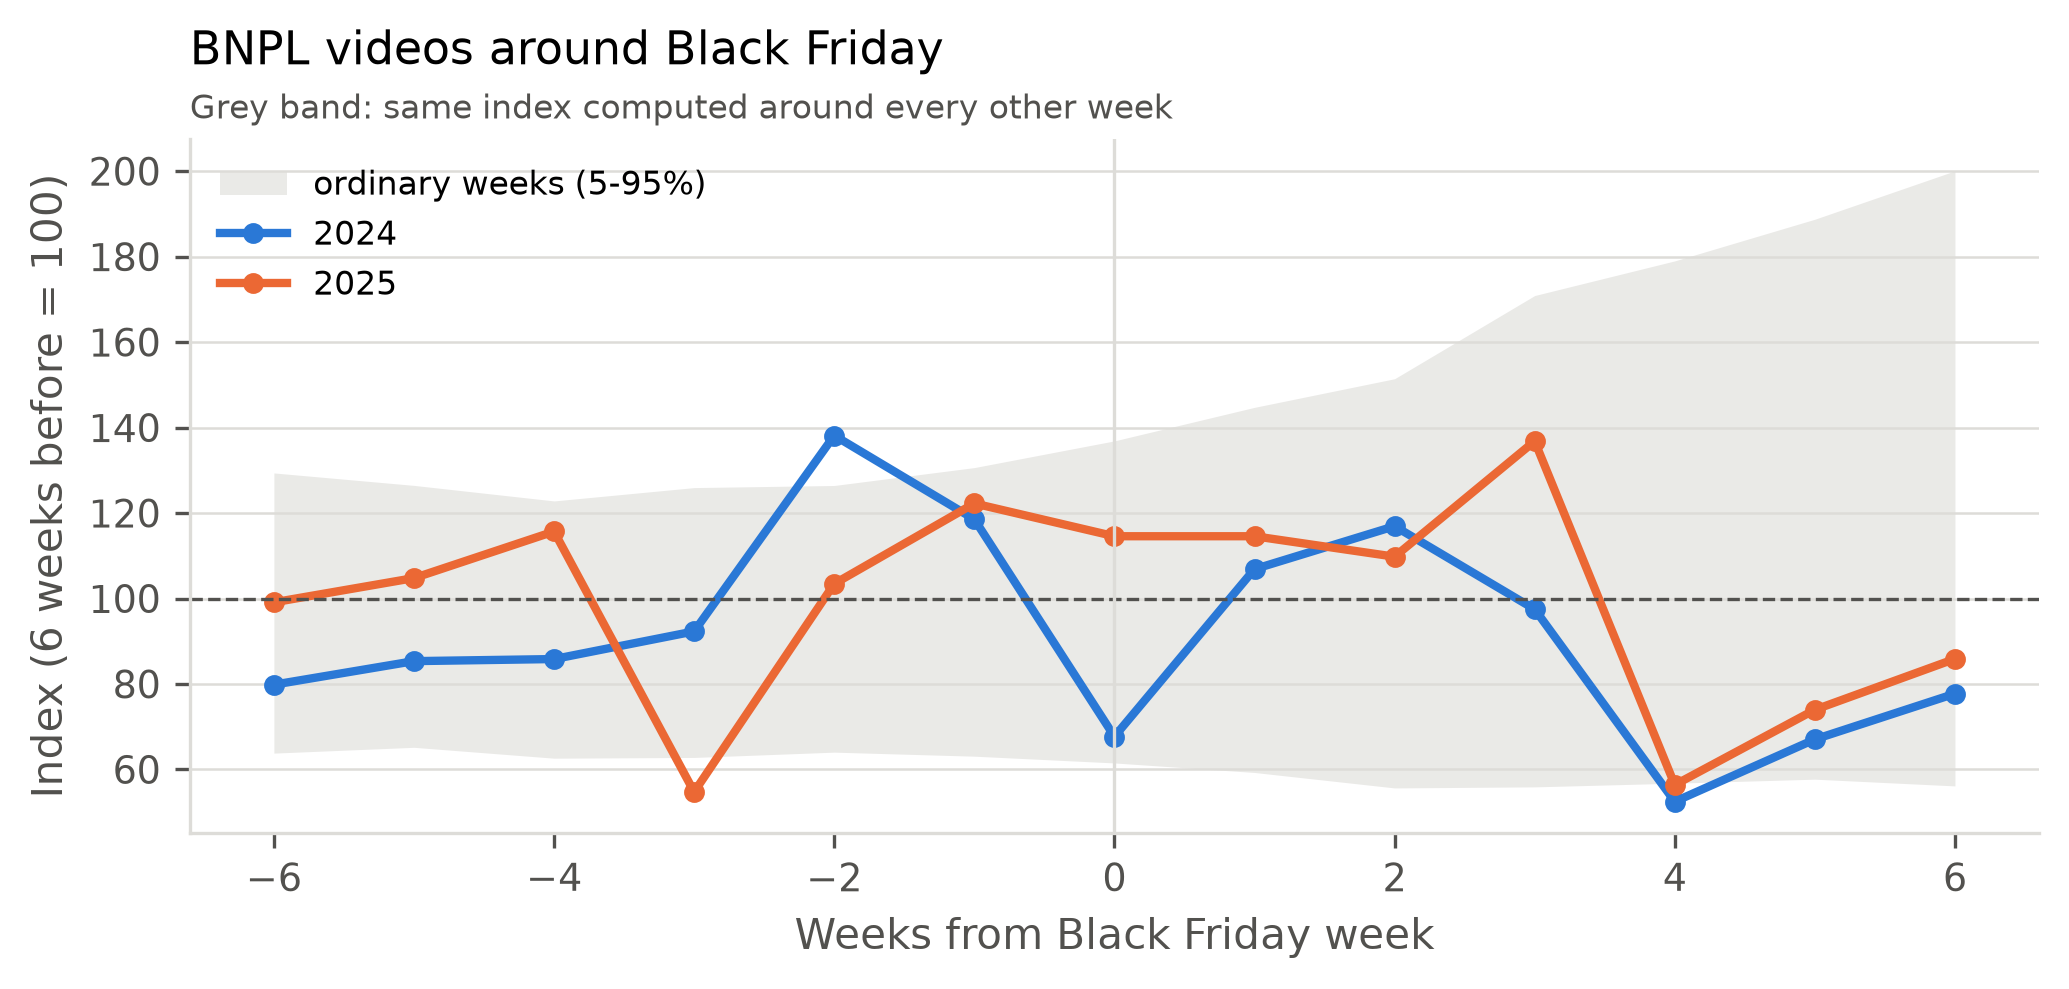

In [9]:
display(tables['black_friday'].pivot_table(index='week_offset', columns='year', values='index').round(0))
show('black_friday')

**Interpretation.** The grey band shows how much the same index varies around ordinary weeks. It is the 5th to 95th percentile over 130 anchor weeks.
- **Black Friday week itself:** inside the ordinary range in both years (68 in 2024 and 115 in 2025, against a range of 62-137).
- **Unusual weeks:** only 2024's rise two weeks before Black Friday (138, above the 95th percentile of 126), and Christmas week (four weeks after) in both years (52 and 56, at or just below the 5th percentile of 57).

Posting volume therefore shows no Black Friday effect beyond normal week-to-week variation. There is a modest pre-sale rise in 2024 and a Christmas dip in both years. The band widens after week 0 because volume grew over the period, so later weeks drift further from the baseline.

Posting volume is not purchase volume, and these data say nothing about how much BNPL is used on Black Friday.

## 7. Context hashtags

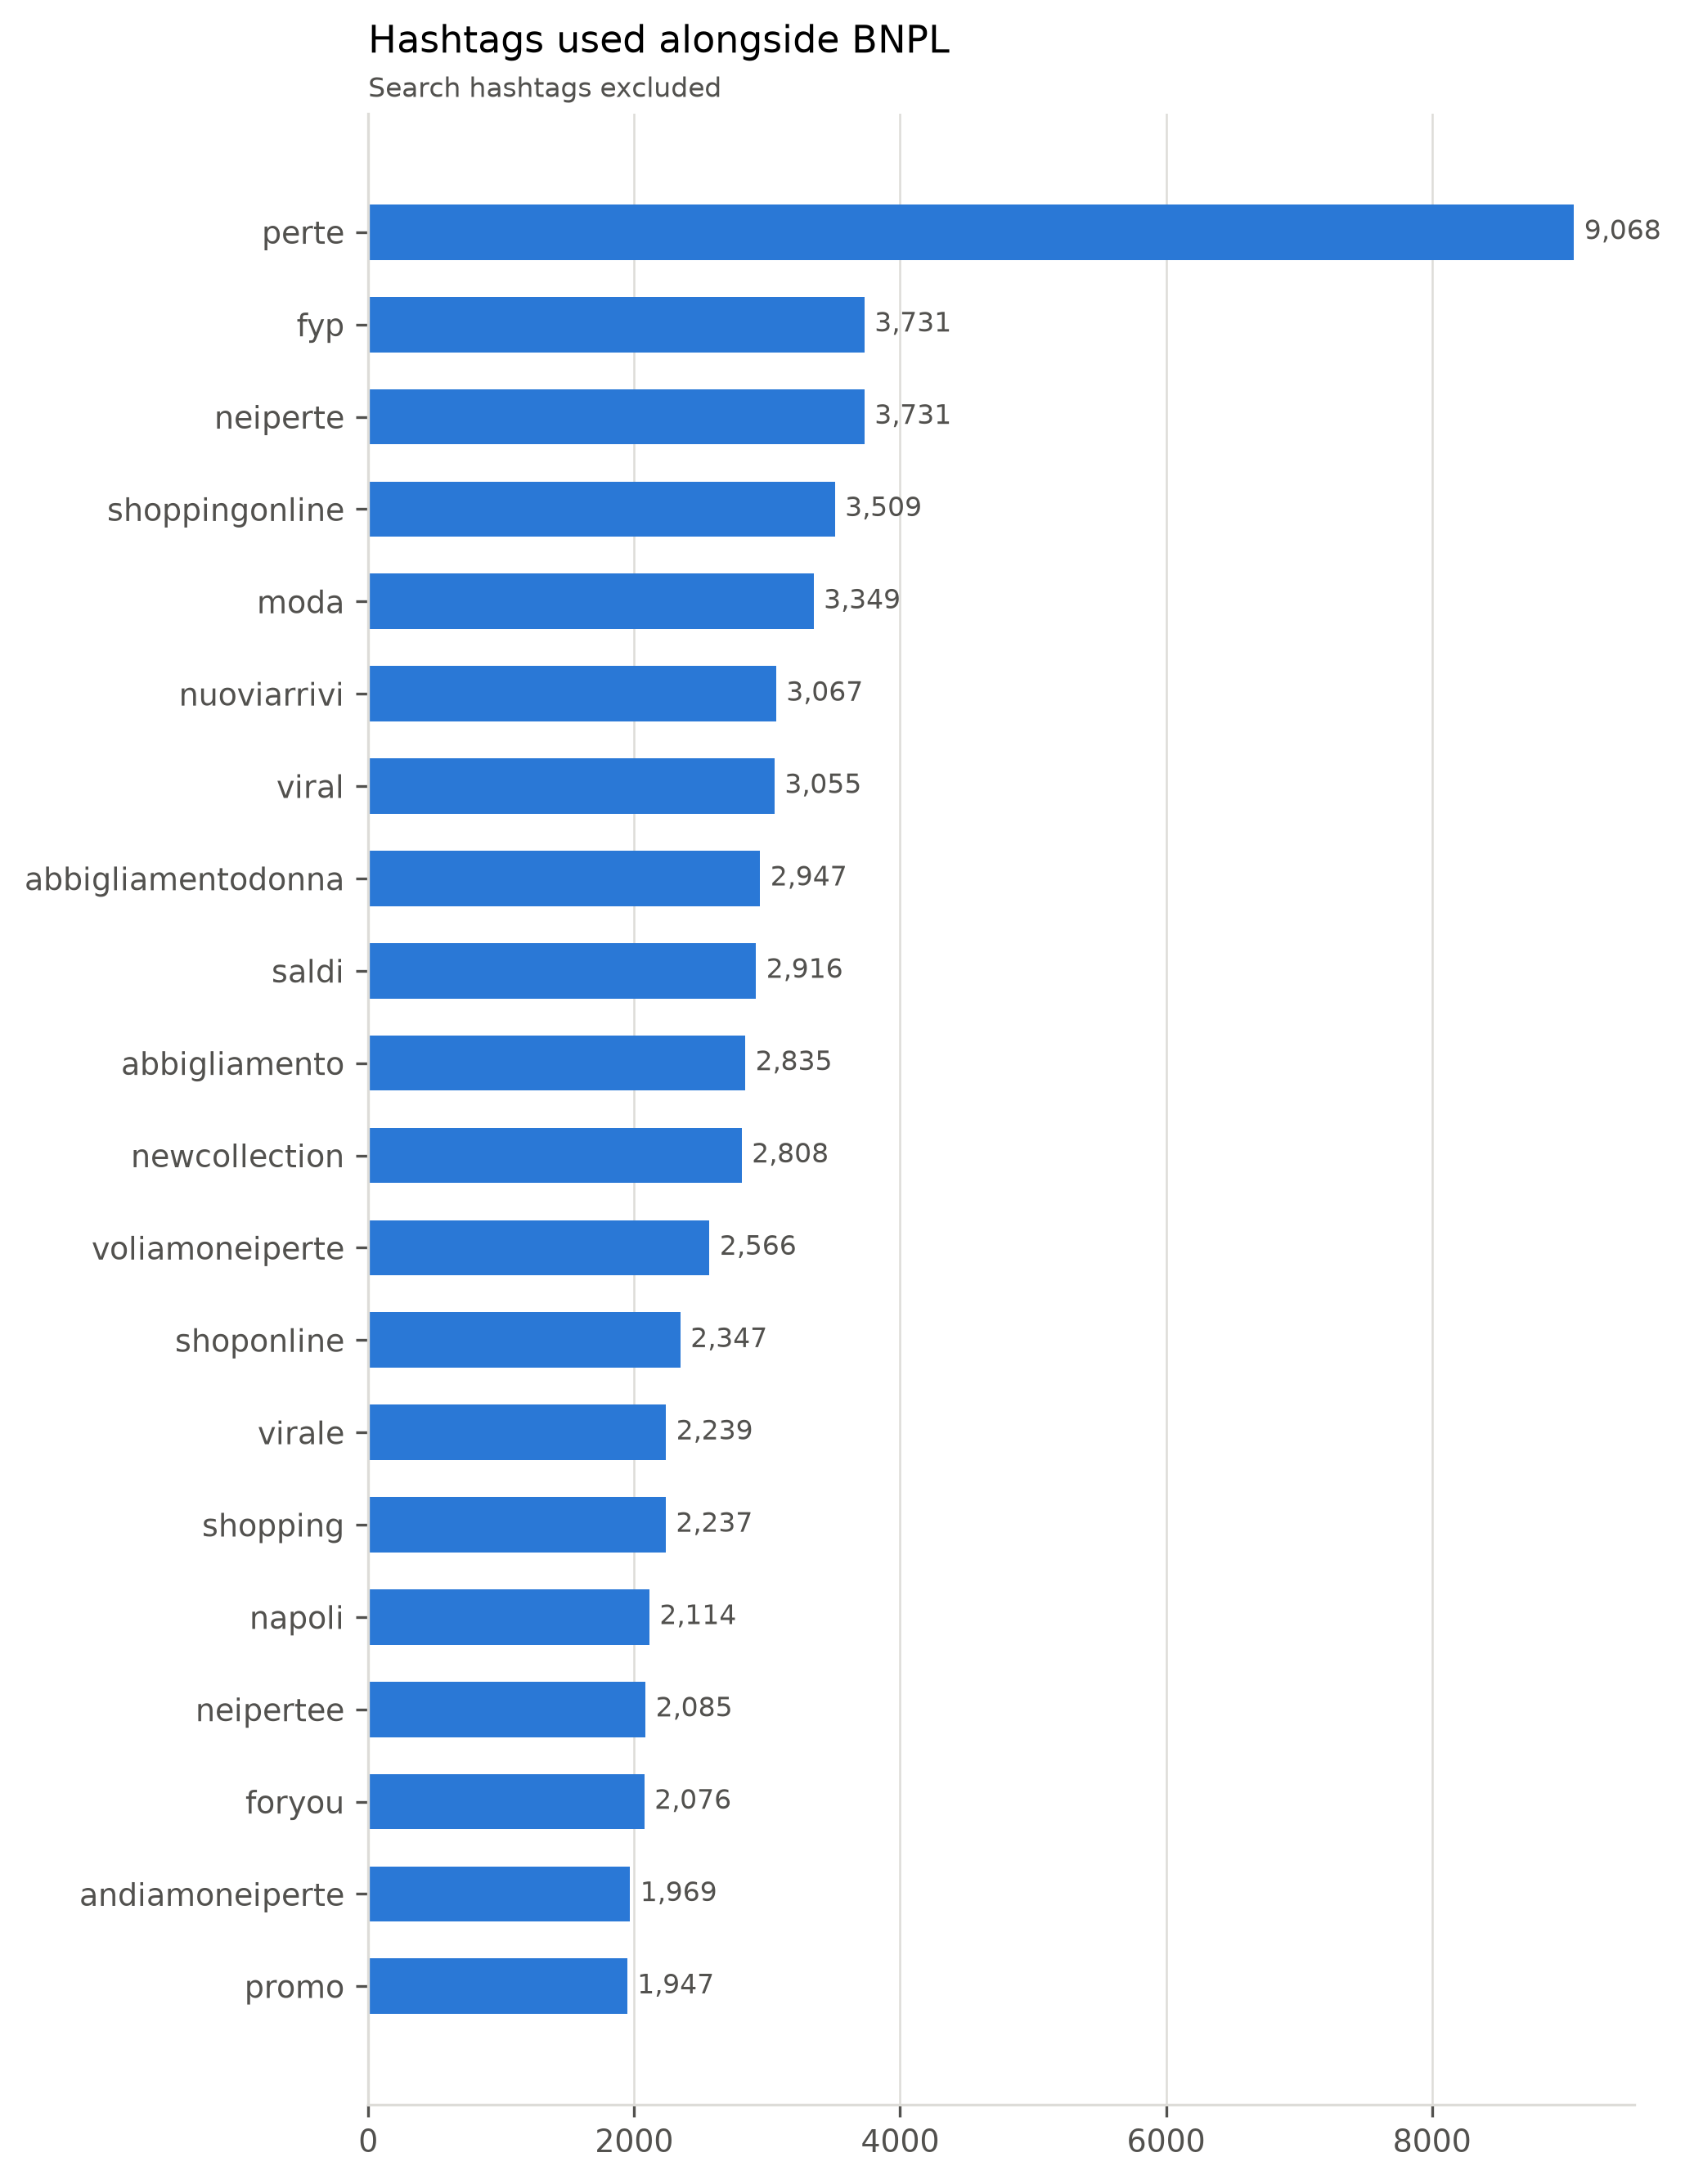

In [10]:
show('top_hashtags')

**Interpretation.** Apart from the search terms, the hashtags used alongside BNPL fall into two groups:
- general reach hashtags: #perte, #neiperte, #fyp, #viral;
- clothing and shoe retail: #moda, #abbigliamento, #nuoviarrivi, #newcollection, #saldi, #shoppingonline.

#napoli is the only place name in the top 20, on 2% of videos. The typical BNPL video is a small fashion retailer showing new stock with "paga in 3 rate".

Fashion is where most of this content comes from, so a fashion checkout is a realistic scenario for the thesis prototype.

## 8. Comments

,comments
video_post_type,
shop_ad,10563
other,5940
financial_commentary,1316
personal_experience,259


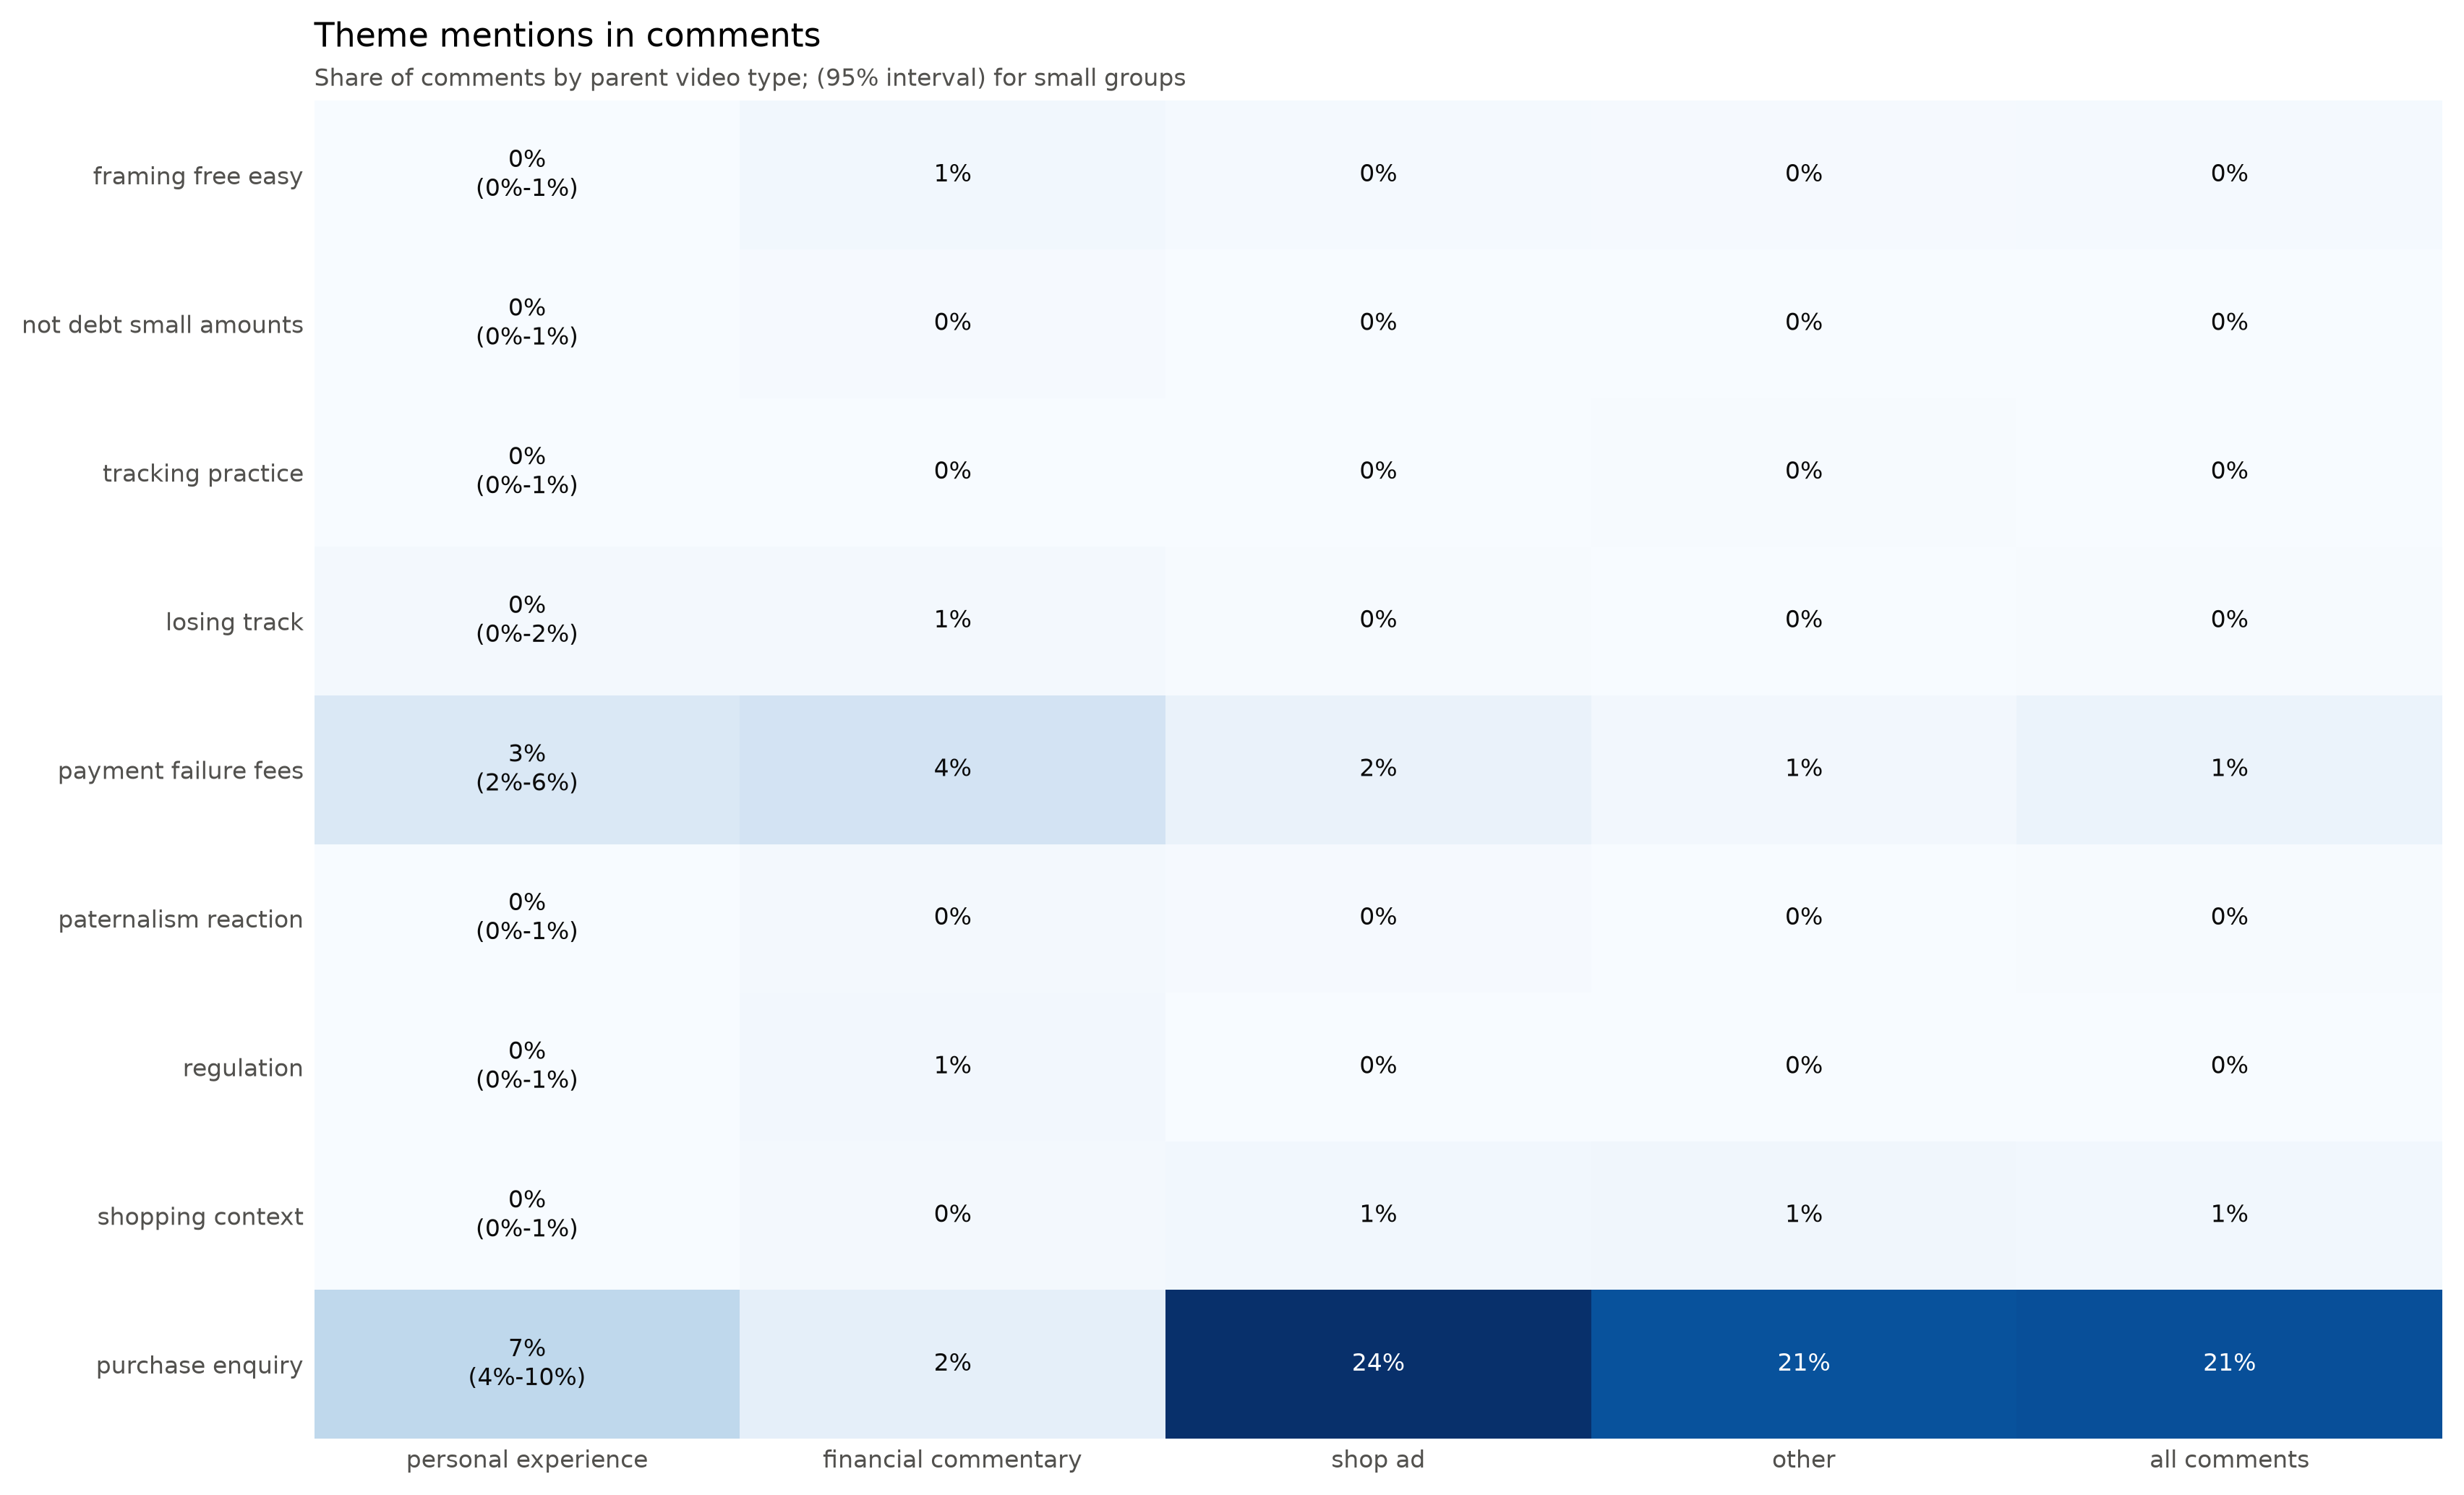

In [11]:
display(result['comments']['video_post_type'].value_counts().rename('comments').to_frame())
show('comment_cues')

**Interpretation.** The 18,078 comments come from 309 videos, and most sit under ads (10,563) or unclassified posts (5,940). Under ads, comments work as customer service: 24.1% (95% interval 23.3-24.9%) ask about price, availability, shipping, or where to buy. Under commentary the figure is 2.1% (1.5-3.1%).

Theme words are rare in comments, because comments are short and the dictionaries are lexical. Payment failure and fees is the most frequent theme: 4.4% (3.4-5.7%) of comments under commentary and 3.5% (1.8-6.5%) under first-person posts, against 1.6% under ads.

Reading comments under commentary videos shows that discussion drifts to wages, the cost of living, and blame ("la gente", "colpa"), rather than to how people keep track of their own installments. The videos were selected for having many comments, so these shares describe popular threads rather than all comments.

For the thesis: TikTok shows how BNPL is sold and how it is criticized, but not how users manage their commitments. That evidence has to come from the interviews and the artefact walk-throughs.

## 9. Before and after CCD2

In [12]:
display(tables['cues_by_period'])

,cue,pre_ccd2
0,framing_free_easy,0.295
1,not_debt_small_amounts,0.009
2,tracking_practice,0.011
3,losing_track,0.004
4,payment_failure_fees,0.006
5,paternalism_reaction,0.001
6,regulation,0.002
7,shopping_context,0.188
8,purchase_enquiry,0.585


**Interpretation.** No post-CCD2 data exists yet: the revised Consumer Credit Directive applies from 20 November 2026, so the table has only the `pre_ccd2` column. This is the baseline. Regulation is mentioned in 0.2% of BNPL videos overall, but in 11% of commentary. Posts explicitly explaining the directive appear from August and September 2026.

Rerun the collection notebook after the end of December 2026, and again after January 2027. That adds the weeks after the directive applies, including Black Friday 2026 and Christmas. The before-and-after table and heatmap (`cues_by_period.png`) then appear automatically.

## 10. Summary for the thesis

**What the TikTok corpus contributes to the thesis** (run of 26 October 2026, January 2024 to August 2026, 97,166 BNPL videos):

1. **BNPL reaches young people on TikTok mainly as a merchant feature.** 91% of BNPL videos are shop ads. The 100 most active accounts produce 47% of the content, and provider accounts are almost absent.
2. **The promoted message is "free and easy".** 31% of ads stress no interest or ease, and almost none mention fees, missed payments, or totals.
3. **Fragmentation is visible at checkout.** Klarna dominates (66% of mentions, growing 6.6 times since early 2024), and 18% of provider videos offer two or more providers side by side.
4. **Critical discourse is small but growing, and it targets the thesis problem.** Its share rose from 0.09% of BNPL videos in 2024 to 0.25% in 2026; the 95% intervals do not overlap. A third of commentary discusses fees and failures, and a fifth discusses losing track of installments. Commentary does not reach fewer viewers per video than ads, but there is far less of it.
5. **TikTok does not show how users track their commitments.** First-person accounts are rare (37 videos) and comments are mostly purchase questions, which supports interviews and artefact elicitation as the main evidence for RQ1 and RQ2.
6. **No Black Friday effect in posting.** Black Friday weeks fall inside the range of ordinary weekly variation.

**Limits.** These points describe one platform, rest on the hypothesis that TikTok content approximates what young adults are exposed to, and use unvalidated keyword labels. The intervals measure how stable each number is, not whether it is biased. See *Validity and bias* at the top of this notebook before citing any number.